# 09 — Conclusões e lacunas

**Para que serve este notebook.** Fecha a mineração (Etapa 1 do `docs/plano_projeto.md`). Junta, num lugar só, o que os notebooks 01 a 08 e as melhorias de confiança do notebook 10 descobriram e responde três perguntas:

1. **Quais são os achados principais**, cada um com o número, o gráfico e a frase para a apresentação? (seção 2: 10 achados)
2. **O que os dados não responderam**, por quê, e qual fonte nova resolveria? (seção 3: tabela de lacunas)
3. **O que entra no painel**, e em qual página? (seção 4: insumo das Etapas 3 e 4)

**A pergunta do projeto.** Quanto dinheiro o seguro obrigatório dos cartórios (Prov. CNJ 227/2026) pode movimentar em Minas Gerais, **e quão certo é esse número?** A primeira metade vem da escada de 9 perguntas do plano (os 10 números do painel); a segunda vem dos notebooks 03 a 08 e 10.

**Regra:** o notebook não muda os 10 números do painel; o que não é a base aparece como **sensibilidade** ou **projeção**, rotulado como tal. **Desde a D-046 (28/10/2026), a base usa as premissas v3:** a chance de déficit e a parte descoberta vêm da capacidade de pagar do titular (M1, notebook 10), e não mais de suposição. Com isso, o déficit, a IS e o prêmio caíram 7,5% (prêmio de R$ 368,7 mil para R$ 341,1 mil), e a contagem "com déficit" foi de ≈ 486 para ≈ 148. Os números abaixo já são os novos.

**De onde vêm os números.** Nada é copiado dos outros notebooks: cada número é recalculado aqui a partir do banco (`gold.fato_mercado_uf`, `gold.interno_serventia` e o silver) e de dez tabelas `gold.analise_*` (as seis da Etapa 2, a sensibilidade de método e três das melhorias de confiança), as mesmas que o pipeline grava. Se o banco já tem essas tabelas, elas são lidas dele; se não, são calculadas agora pelas mesmas funções do pipeline (`src/analise/tabelas.py`, uns 15 minutos). A primeira linha da saída abaixo diz qual foi o caso. As poucas exceções (números citados de outro notebook) estão marcadas no texto.

**Termos usados** (explicados nos notebooks de origem): mediana, percentil (P5, P10, P90, P95), faixa P5–P95, Monte Carlo, tornado, índice de Gini, k-means, lift, MAE, R², projeção, sensibilidade.

**Dados:** banco do pipeline (dados da carga de 19/10/2026, coletados em 17 e 18/10; banco refeito em 28/10), premissas v3 (`config/premissas/premissas_v003.yaml`, D-046), regra de classe v2 (Classe 1 até R$ 300 mil por semestre), cenário do STF "mantém". Os gráficos também vão em PNG para `docs/qa/analises/` (`09_*.png`).

## 1. Os 10 números oficiais

A tabela abaixo é o ponto de partida: os números do painel no nível base e nos dois "cantos" (todas as premissas no mínimo e todas no máximo), lidos de `gold.fato_mercado_uf`. O teto teórico é o passivo das obrigadas × a taxa do nível (2% na base), como se nenhuma serventia tivesse bens.

In [1]:
import sys
import textwrap
from pathlib import Path

raiz = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(raiz))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display

from src import estado
from src.analise import conclusoes as cc, config, dados, graficos as g, melhorias as mh, padroes, sensibilidade as se, vacancia as va
from src.notebooks import conectar, ler

g.estilo()
cfg = config()
con = conectar()
sv = dados.serventias(con)
of = cc.numeros_oficiais(con)
tabs, origem = cc.carregar(con)
semente_premissas = estado.ler_semente()          # config/premissas/premissas_v003.yaml (D-046)
cenarios = yaml.safe_load((raiz / "config/cenarios_stf.yaml").read_text(encoding="utf-8"))
limites = yaml.safe_load((raiz / "config/regras_classificacao.yaml").read_text(encoding="utf-8"))["versoes"]["v2"]["limites"]
FONTE = "dados da carga de 19/10/2026 (banco refeito em 28/10); premissas v3; regra v2; cenário do STF \"mantém\""
print(f"Tabelas gold.analise_*: {origem}. " + "; ".join(f"{t}: {g.num(len(d))} linhas" for t, d in tabs.items()) + ".")
display(g.tabela(of.reset_index(names="número"), {"min": "num1", "base": "num1", "max": "num1"})
        .rename(columns={"min": "premissas no mínimo", "base": "base (painel)", "max": "premissas no máximo"}))

Tabelas gold.analise_*: banco (gold.analise_*). analise_regras: 10 linhas; analise_grupos: 2.444 linhas; analise_clt_modelo: 2.444 linhas; analise_previsao: 107 linhas; analise_tornado: 11 linhas; analise_monte_carlo: 6 linhas; analise_sensibilidade_metodo: 6 linhas; analise_capacidade_calibracao: 9 linhas; analise_sinistro: 6 linhas; analise_premio_cenarios: 3 linhas.


nivel,número,premissas no mínimo,base (painel),premissas no máximo
0,serventias ativas,"2.525,0","2.525,0","2.525,0"
1,empregados CLT,"12.134,0","12.134,0","12.134,0"
2,obrigadas,"1.103,0","1.121,3","1.159,0"
3,passivo (todas),"285.531.002,9","311.866.725,1","355.227.633,3"
4,passivo (obrigadas),"216.366.498,5","238.104.260,6","279.814.003,1"
5,com déficit (esperado),"116,7","147,9","294,6"
6,déficit,"20.684.127,0","34.106.243,7","78.956.450,1"
7,IS do mercado,"5.171.031,8","17.053.121,8","55.269.515,1"
8,prêmio anual,"51.710,3","341.062,4","1.934.433,0"
9,teto teórico,"2.163.665,0","4.762.085,2","9.793.490,1"


## 2. Os 10 achados principais

Cada achado tem: **a pergunta**, o **cálculo** (curto, com a origem), **o número**, **o gráfico** e **a frase para a apresentação**, com a limitação. Os achados 1 a 3 respondem "quanto e quão certo"; o 4 e o 6, "quem é o cliente"; o 5, "a seguradora tem lucro" (pergunta 9); 7 a 9, "o que pode mudar o número"; o 10, "dá para levar a outros estados". Desde 2026-10-28, os achados 2 a 5 incluem as melhorias de confiança do notebook 10, e todos usam as premissas v3 (D-046).

### Achado 1 — O seguro cobre uma fatia pequena da dívida trabalhista

**A pergunta.** Da dívida trabalhista dos cartórios até o prêmio das seguradoras, quanto sobra em cada degrau da escada?

**O cálculo.** Os degraus 4 a 8 da escada, na base (`gold.fato_mercado_uf`). Cada degrau é uma parte do anterior: só as obrigadas entram; só a parte sem bens vira déficit; só a parte do déficit que escolhe seguro vira IS (importância segurada, o valor garantido); o prêmio é a IS × a taxa (2%).

,degrau,valor,% do passivo das obrigadas
0,4. Passivo de todas as serventias,"R$ 311,9 mi","131,0%"
1,4. Passivo das obrigadas,"R$ 238,1 mi","100,0%"
2,6. Déficit (sem bens que cubram),"R$ 34,1 mi","14,3%"
3,7. IS do mercado (vira seguro),"R$ 17,1 mi","7,2%"
4,8. Prêmio anual do mercado,"R$ 341,1 mil","0,1%"
5,Teto teórico do prêmio,"R$ 4,8 mi","2,0%"


Prêmio ÷ teto teórico: 7,2%; IS ÷ passivo das obrigadas: 7,2%; obrigadas: 1.121,3 de 2.525 serventias ativas (44,4%).


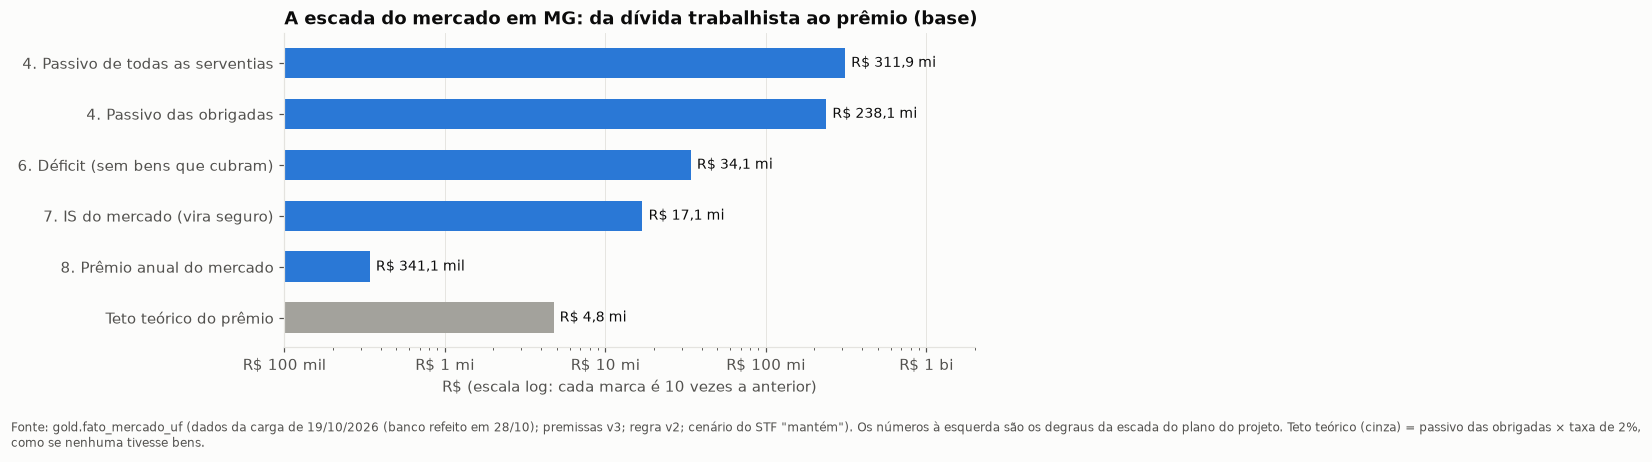

In [2]:
b = of["base"]
degraus = pd.DataFrame({"degrau": ["4. Passivo de todas as serventias", "4. Passivo das obrigadas", "6. Déficit (sem bens que cubram)",
                                   "7. IS do mercado (vira seguro)", "8. Prêmio anual do mercado", "Teto teórico do prêmio"],
                        "valor": [b["passivo (todas)"], b["passivo (obrigadas)"], b["déficit"], b["IS do mercado"],
                                  b["prêmio anual"], b["teto teórico"]]})
degraus["% do passivo das obrigadas"] = degraus.valor / b["passivo (obrigadas)"]
display(g.tabela(degraus, {"valor": "reais", "% do passivo das obrigadas": "pct"}))
print(f"Prêmio ÷ teto teórico: {g.pct(b['prêmio anual'] / b['teto teórico'])}; IS ÷ passivo das obrigadas: "
      f"{g.pct(b['IS do mercado'] / b['passivo (obrigadas)'])}; obrigadas: {g.num(b['obrigadas'], 1)} de {g.num(b['serventias ativas'])} "
      f"serventias ativas ({g.pct(b['obrigadas'] / b['serventias ativas'])}).")

fig, ax = plt.subplots(figsize=(9, 3.8))
d = degraus.iloc[::-1]
cores = [g.CINZA] + [g.AZUL["medio"]] * 5
barras = ax.barh(d.degrau, d.valor, color=cores, height=0.6)
ax.bar_label(barras, [g.reais(v) for v in d.valor], padding=4, fontsize=9)
ax.set_xscale("log")
ax.set_xlim(1e5, 2e9)
ax.set_xticks([1e5, 1e6, 1e7, 1e8, 1e9], [g.reais(v, 0) for v in [1e5, 1e6, 1e7, 1e8, 1e9]])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("R$ (escala log: cada marca é 10 vezes a anterior)")
ax.grid(axis="y", visible=False)
ax.set_title("A escada do mercado em MG: da dívida trabalhista ao prêmio (base)")
fig.tight_layout()
g.nota(fig, f"Fonte: gold.fato_mercado_uf ({FONTE}). Os números à esquerda são os degraus da escada do plano do projeto. "
            "Teto teórico (cinza) = passivo das obrigadas × taxa de 2%,\ncomo se nenhuma tivesse bens.")
g.salvar(fig, "09_escada_do_mercado")
plt.show()

**O número.** O passivo das 1.121 obrigadas é de **R$ 238,1 mi**. Dele, R$ 34,1 mi (14,3%) ficam sem cobertura (déficit), e R$ 17,1 mi (7,2%) viram seguro. O prêmio anual é de **R$ 341,1 mil**, 7,2% do teto teórico de R$ 4,76 mi. As obrigadas são 44,4% das 2.525 serventias ativas.

**A frase para a apresentação.** *"Se os cartórios obrigados de MG fechassem, deveriam R$ 238 milhões aos empregados. O seguro garantiria R$ 17 milhões disso e renderia cerca de R$ 340 mil por ano às seguradoras: um mercado pequeno."*

**Limitação.** Os degraus 5 e 6 vêm da renda declarada ao CNJ (M1), que não é patrimônio; os degraus 7 e 8 dependem de suposições sem fonte (achados 2 e 3). Os degraus 1 a 4 vêm de dados públicos (notebook 01: fontes completas e coerentes).

### Achado 2 — A faixa provável do prêmio é de R$ 215 a 687 mil, e não de R$ 52 mil a R$ 1,9 mi

**A pergunta.** O prêmio base depende de suposições. Quão larga é, de verdade, a incerteza?

**O cálculo.** O notebook 08 sorteou 200 mil combinações das seis suposições dos passos 5 a 8, cada uma com uma distribuição triangular (mínimo, base como o valor mais provável, máximo), e ficou com a faixa P5–P95: o intervalo que contém 90% dos sorteios (`gold.analise_monte_carlo`). Os "cantos oficiais" do painel põem **todas** as premissas no mínimo ou no máximo ao mesmo tempo.

,faixa,de,ate,largura
0,cantos oficiais: todas as premissas no mínimo ...,"R$ 51,7 mil","R$ 1,9 mi","R$ 1,9 mi"
1,"Monte Carlo, P5–P95: seis suposições independe...","R$ 215,0 mil","R$ 687,1 mil","R$ 472,1 mil"
2,"Monte Carlo, P5–P95: patrimônio junto (sensibi...","R$ 197,2 mil","R$ 748,4 mil","R$ 551,2 mil"


Base: R$ 341,1 mil; mediana dos sorteios (P50): R$ 397,3 mil. A faixa P5–P95 é 4,0 vezes mais estreita que a dos cantos oficiais. 200.000 sorteios, semente 20261022.


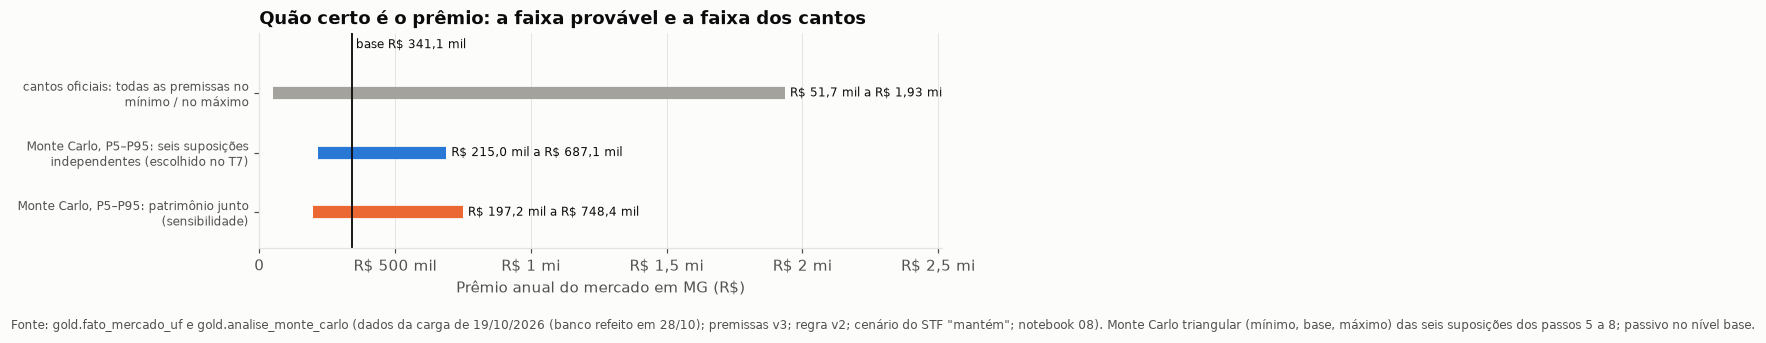

Por cenário do STF (M7, notebook 10): mantem: R$ 341,1 mil (P5–P95 R$ 215,0 mil a R$ 687,1 mil); suspende_8_17: R$ 0 (P5–P95 R$ 0 a R$ 0); parcial: R$ 170,5 mil (P5–P95 R$ 107,5 mil a R$ 343,6 mil).


In [3]:
mc = tabs["analise_monte_carlo"]
pm = mc[mc.medida == "premio"].set_index("variante")
faixas_premio = pd.DataFrame([
    {"faixa": "cantos oficiais: todas as premissas no mínimo / no máximo", "de": of.loc["prêmio anual", "min"], "ate": of.loc["prêmio anual", "max"]},
    {"faixa": "Monte Carlo, P5–P95: seis suposições independentes (escolhido no T7)", "de": pm.loc["independentes", "p05"], "ate": pm.loc["independentes", "p95"]},
    {"faixa": "Monte Carlo, P5–P95: patrimônio junto (sensibilidade)", "de": pm.loc["patrimônio junto", "p05"], "ate": pm.loc["patrimônio junto", "p95"]}])
faixas_premio["largura"] = faixas_premio.ate - faixas_premio.de
display(g.tabela(faixas_premio, {"de": "reais", "ate": "reais", "largura": "reais"}))
print(f"Base: {g.reais(b['prêmio anual'])}; mediana dos sorteios (P50): {g.reais(pm.loc['independentes', 'p50'])}. "
      f"A faixa P5–P95 é {g.num(faixas_premio.largura[0] / faixas_premio.largura[1], 1)} vezes mais estreita que a dos cantos oficiais. "
      f"{g.num(pm.loc['independentes', 'n_sorteios'])} sorteios, semente {pm.loc['independentes', 'semente']}.")

fig, ax = plt.subplots(figsize=(9, 2.9))
cores = [g.CINZA, g.AZUL["medio"], g.CORES[1]]
for i, (r, cor) in enumerate(zip(faixas_premio.itertuples(), cores)):
    y = 2 - i
    ax.plot([r.de, r.ate], [y, y], color=cor, linewidth=8, solid_capstyle="butt")
    ax.text(r.ate + 2e4, y, f"{g.reais(r.de)} a {g.reais(r.ate, 2 if r.ate >= 1e6 else 1)}".replace("$", r"\$"), ha="left", va="center", fontsize=8, color=g.TEXTO)
ax.axvline(b["prêmio anual"], color=g.TEXTO, linewidth=1.2)
ax.text(b["prêmio anual"], 2.75, f" base {g.reais(b['prêmio anual'])}".replace("$", r"\$"), fontsize=8)
ax.set_yticks([2, 1, 0], [textwrap.fill(t, 38) for t in faixas_premio.faixa], fontsize=8)
ax.set_ylim(-0.6, 3.0)
g.eixo_reais(ax, "x")
ax.set_xlim(0, of.loc["prêmio anual", "max"] * 1.3)
ax.set_xlabel("Prêmio anual do mercado em MG (R$)")
ax.grid(axis="y", visible=False)
ax.set_title("Quão certo é o prêmio: a faixa provável e a faixa dos cantos")
fig.tight_layout()
g.nota(fig, f"Fonte: gold.fato_mercado_uf e gold.analise_monte_carlo ({FONTE}; notebook 08). Monte Carlo triangular "
            "(mínimo, base, máximo) das seis suposições dos passos 5 a 8; passivo no nível base.")
g.salvar(fig, "09_faixa_do_premio")
plt.show()
pcs = tabs["analise_premio_cenarios"].set_index("cenario")
print("Por cenário do STF (M7, notebook 10): " + "; ".join(
    f"{c}: {g.reais(r.premio_base)} (P5–P95 {g.reais(r.premio_p05)} a {g.reais(r.premio_p95)})" for c, r in pcs.iterrows()) + ".")

**O número.** Faixa P5–P95: **R$ 215,0 mil a R$ 687,1 mil**, 4,0 vezes mais estreita que a dos cantos oficiais (R$ 51,7 mil a R$ 1,93 mi). A mediana dos sorteios (R$ 397,3 mil) fica acima da base, porque as faixas das suposições são mais longas para cima. Se as quatro premissas de patrimônio andarem juntas (sensibilidade), a faixa vai a R$ 197,2 mil a R$ 748,4 mil. Com as premissas v3 (D-046), a faixa ficou mais estreita (era R$ 206 a 736 mil): a chance de déficit e a parte descoberta passaram a vir de dado, e a faixa delas é a do horizonte de saldo (6 a 24 meses).

**A frase para a apresentação.** *"O prêmio provável fica entre R$ 215 mil e R$ 690 mil por ano. Os extremos de R$ 52 mil e R$ 1,9 milhão exigem que tudo dê errado (ou certo) ao mesmo tempo, o que quase nunca acontece."*

**O risco jurídico (M7, notebook 10).** A faixa não inclui a ADI 8015, cujo efeito é **binário**. Mantida a regra, valem os números acima. No cenário hipotético "parcial" (metade do déficit exigida), tudo cai pela metade (R$ 171 mil; R$ 108 a 344 mil). Com os arts. 8º a 17 suspensos, o mercado vai a **zero**. Em 28/10/2026 não havia liminar nem decisão de mérito: as duas decisões de 22/10 admitiram terceiros interessados, e o processo está concluso ao relator. O painel deve mostrar o prêmio "se a regra for mantida", com o cenário do STF ao lado.

**Limitação.** A faixa só mede a incerteza das suposições, com distribuições que também são suposições (triangular). A hierarquia de exibição (base > P5–P95 > cantos) é a D-042, proposta e ainda não aprovada pelo autor.

### Achado 3 — A taxa e a adesão ao seguro decidem o tamanho do mercado

**A pergunta.** Qual premissa mais mexe no prêmio?

**O cálculo.** Tornado do notebook 08 (`gold.analise_tornado`): cada premissa vai sozinha do mínimo ao máximo, com as outras no base, e o prêmio é recalculado pelas funções do modelo. A amplitude é a distância entre o prêmio no mínimo e no máximo.

,ordem,rotulo,grupo,"prêmio, menor","prêmio, maior",amplitude
0,1,Taxa do seguro,suposição (passos 5 a 8),"R$ 170,5 mil","R$ 596,9 mil","R$ 426,3 mil"
1,2,Parte do déficit que escolhe seguro,suposição (passos 5 a 8),"R$ 170,5 mil","R$ 477,5 mil","R$ 307,0 mil"
2,3,"Chance de déficit, Classe 3",suposição (passos 5 a 8),"R$ 339,5 mil","R$ 598,7 mil","R$ 259,2 mil"
3,4,"Parte descoberta, Classe 3",suposição (passos 5 a 8),"R$ 249,3 mil","R$ 341,1 mil","R$ 91,7 mil"
4,5,"Chance de déficit, Classe 2",suposição (passos 5 a 8),"R$ 324,1 mil","R$ 386,9 mil","R$ 62,8 mil"
5,6,Férias vencidas pendentes (fração),passivo e universo,"R$ 313,2 mil","R$ 369,0 mil","R$ 55,8 mil"
6,7,"Parte descoberta, Classe 2",suposição (passos 5 a 8),"R$ 332,9 mil","R$ 355,4 mil","R$ 22,5 mil"
7,8,INSS sobre o aviso prévio,passivo e universo,"R$ 341,1 mil","R$ 358,5 mil","R$ 17,4 mil"
8,9,Intervenção e diligência dentro do universo,passivo e universo,"R$ 341,1 mil","R$ 351,5 mil","R$ 10,5 mil"
9,10,Peso das serventias de classe indeterminada,passivo e universo,"R$ 339,5 mil","R$ 341,8 mil","R$ 2,3 mil"


As 2 primeiras (Taxa do seguro, Parte do déficit que escolhe seguro) somam 58,4% da soma das amplitudes; as premissas do passivo e do universo mexem no máximo 16,4% do prêmio base.


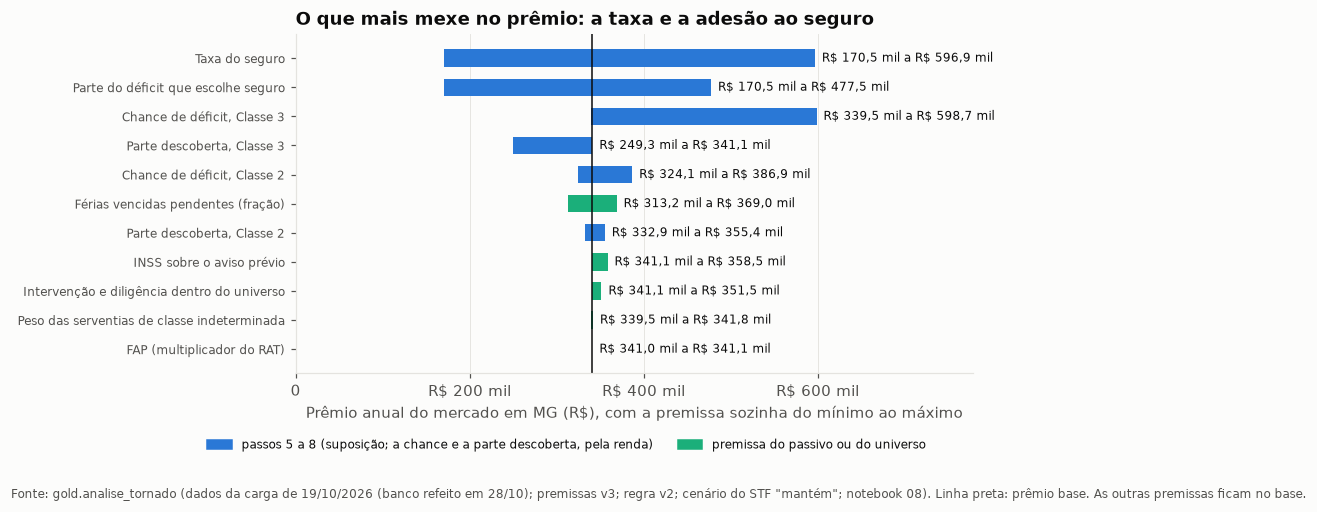

Grade taxa × adesão (M8, notebook 10): de R$ 85,3 mil a R$ 835,6 mil; a SES da SUSEP não publica a importância segurada, então a taxa não tem fonte pública.


In [4]:
tor = tabs["analise_tornado"].sort_values("ordem")
tor = tor.assign(de=tor[["premio_no_min", "premio_no_max"]].min(axis=1), ate=tor[["premio_no_min", "premio_no_max"]].max(axis=1))
display(g.tabela(tor[["ordem", "rotulo", "grupo", "de", "ate", "amplitude"]], {"de": "reais", "ate": "reais", "amplitude": "reais"})
        .rename(columns={"de": "prêmio, menor", "ate": "prêmio, maior"}))
sup = tor[tor.grupo.str.startswith("suposição")]
print(f"As 2 primeiras ({', '.join(tor.rotulo.iloc[:2])}) somam {g.pct(tor.amplitude.iloc[:2].sum() / tor.amplitude.sum())} da soma das amplitudes; "
      f"as premissas do passivo e do universo mexem no máximo {g.pct(tor[~tor.grupo.str.startswith('suposição')].amplitude.max() / b['prêmio anual'])} "
      f"do prêmio base.")

fig, ax = plt.subplots(figsize=(9, 4.4))
tt = tor.iloc[::-1]
y = np.arange(len(tt))
cores = [g.AZUL["medio"] if s.startswith("suposição") else g.CORES[2] for s in tt.grupo]
ax.barh(y, tt.ate - tt.de, left=tt.de, color=cores, height=0.6)
for i, r in enumerate(tt.itertuples()):
    ax.text(r.ate + 8e3, i, f"{g.reais(r.de)} a {g.reais(r.ate)}".replace("$", r"\$"), va="center", fontsize=8)
ax.axvline(b["prêmio anual"], color=g.TEXTO, linewidth=1)
ax.set_yticks(y, tt.rotulo, fontsize=8)
ax.set_xlim(0, tor.ate.max() * 1.3)
ax.set_xticks(np.arange(0, tor.ate.max() * 1.3, 2e5))
g.eixo_reais(ax, "x")
ax.set_xlabel("Prêmio anual do mercado em MG (R$), com a premissa sozinha do mínimo ao máximo")
ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=g.AZUL["medio"], label="passos 5 a 8 (suposição; a chance e a parte descoberta, pela renda)"),
                   Patch(color=g.CORES[2], label="premissa do passivo ou do universo")], loc="upper center", bbox_to_anchor=(0.4, -0.16), ncol=2, fontsize=8)
ax.set_title("O que mais mexe no prêmio: a taxa e a adesão ao seguro")
fig.tight_layout()
g.nota(fig, f"Fonte: gold.analise_tornado ({FONTE}; notebook 08). Linha preta: prêmio base. As outras premissas ficam no base.")
g.salvar(fig, "09_tornado_resumo")
plt.show()
grade = mh.grade_taxa_adesao(float(b["déficit"]), semente_premissas)
print(f"Grade taxa × adesão (M8, notebook 10): de {g.reais(grade.min().min())} a {g.reais(grade.max().max())}; a SES da SUSEP não "
      "publica a importância segurada, então a taxa não tem fonte pública.")

**O número.** Sozinha, a **taxa do seguro** leva o prêmio de **R$ 170,5 mil a R$ 596,9 mil**; a **parte do déficit que escolhe seguro**, de R$ 170,5 mil a R$ 477,5 mil. As duas somam 58,4% da soma das amplitudes (eram 47,1% com a v2). Em terceiro vem a chance de déficit da Classe 3 (R$ 339,5 a 598,7 mil), agora pelo horizonte de saldo da M1. A premissa do passivo ou do universo que mais mexe (férias vencidas pendentes) muda o prêmio em no máximo 16,4% da base.

**A frase para a apresentação.** *"O que mais pesa não são os dados dos cartórios, e sim duas coisas que ninguém sabe ainda: quanto as seguradoras vão cobrar e quantos cartórios vão preferir o seguro à fiança ou aos próprios bens."*

**Há fonte para a taxa? (M8, notebook 10).** Não. A SES da SUSEP publica prêmios e sinistros por ramo, mas **não a importância segurada**, de onde sairia a taxa média (prêmio ÷ IS). Isso foi conferido em 28/10 no índice do arquivo completo (40 tabelas) e no dicionário de campos. Por isso, o simulador deve mostrar o prêmio numa **grade taxa × adesão**, de R$ 85 mil (1% e 25%) a R$ 836 mil (3,5% e 70%), com a base no centro.

**Limitação.** O tornado move uma premissa por vez; combinações aparecem no Monte Carlo (achado 2). Os mínimos e máximos da taxa, da adesão e do horizonte de saldo também são suposições (D-016, D-046).

### Achado 4 — Mercado concentrado: o cliente do seguro são as providas grandes

**A pergunta.** O risco está espalhado ou concentrado? E que tipo de cartório é o cliente do seguro?

**O cálculo.** (a) Entre as serventias com peso no universo de obrigadas, ordenamos do maior para o menor e medimos a parte do total nas 10% maiores (`config/analise.yaml`, `sensibilidade.topo_concentracao`) e o **índice de Gini** (0 = todos iguais; perto de 1 = quase tudo numa só). (b) Os 6 grupos do k-means do notebook 04 (`gold.analise_grupos`), com a parte de cada grupo nas serventias, nas obrigadas, no passivo das obrigadas (dado) e no déficit (desde a D-046, pela capacidade de pagar). (c) O déficit pela capacidade de pagar serventia a serventia (M1 e M10, notebook 10).

,medida,gini,parte dos 10% maiores
0,passivo das obrigadas,"0,63","53,5%"
1,déficit esperado,"0,73","63,0%"


Serventias com peso no universo: 1.130; os 10% maiores são ≈ 113 serventias.


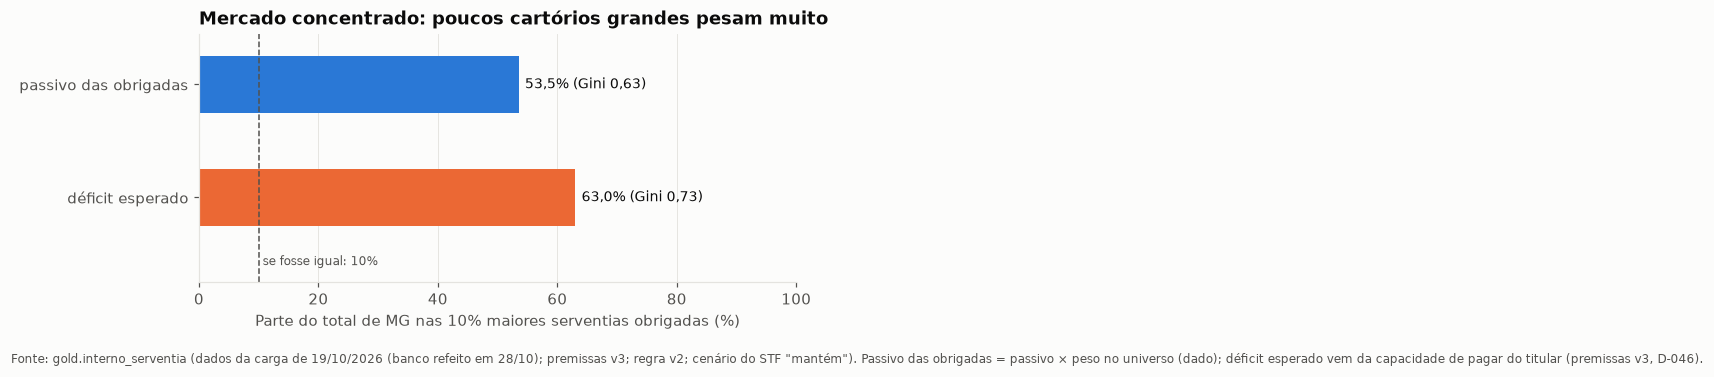

,grupo,nome,grupo_alvo,serventias,% das serventias agrupadas,% das obrigadas de MG,% do passivo das obrigadas (dado),"% do déficit (pela renda, D-046)",déficit por obrigada
0,1,vagas pequenas,False,688,"28,2%","0,0%","0,0%","0,0%",—
1,2,providas pequenas (Notas e RCPN),False,634,"25,9%","26,8%","9,3%","5,2%","R$ 5,9 mil"
2,3,providas médias de uma atribuição,False,578,"23,6%","34,2%","12,9%","7,6%","R$ 6,8 mil"
3,4,"registro completo (RI, RTD e RCPJ)",False,188,"7,7%","14,2%","9,5%","9,2%","R$ 19,6 mil"
4,5,vagas grandes,False,91,"3,7%","0,0%","0,0%","0,0%",—
5,6,providas grandes,True,265,"10,8%","23,3%","67,4%","77,6%","R$ 101,4 mil"


Grupo-alvo: 6 (providas grandes). Serventias fora do agrupamento (sem receita de 2025 > 0 ou sem CLT): 81.


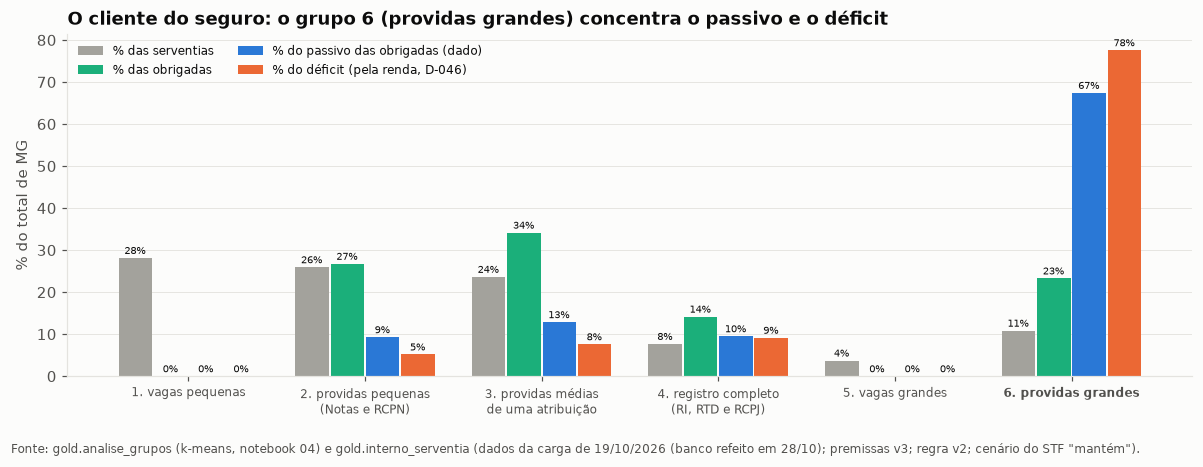

Pela capacidade de pagar (M1, 12 meses de saldo; notebook 10): déficit da Classe 3 R$ 29,4 mi de R$ 34,1 mi.


In [5]:
topo = cfg["sensibilidade"]["topo_concentracao"]
conc = cc.concentracao(sv, topo)
obr = sv[sv.peso_universo > 0]
n_topo = int(round(topo * obr.passivo.notna().sum()))
display(g.tabela(conc, {"gini": "num2", "parte_do_topo": "pct"}).rename(columns={"parte_do_topo": f"parte dos {round(100 * topo)}% maiores"}))
print(f"Serventias com peso no universo: {g.num(len(obr))}; os {round(100 * topo)}% maiores são ≈ {g.num(n_topo)} serventias.")

fig, ax = plt.subplots(figsize=(7.5, 3.2))
barras = ax.barh(conc.medida[::-1], 100 * conc.parte_do_topo[::-1], color=[g.CORES[1], g.AZUL["medio"]], height=0.5)
ax.bar_label(barras, [f"{g.pct(v)} (Gini {g.num(gi, 2)})" for v, gi in zip(conc.parte_do_topo[::-1], conc.gini[::-1])], padding=4, fontsize=9)
ax.axvline(100 * topo, color=g.TEXTO_2, linestyle="--", linewidth=1)
ax.set_ylim(-0.75, 1.45)
ax.text(100 * topo, -0.6, f" se fosse igual: {round(100 * topo)}%", fontsize=8, color=g.TEXTO_2)
ax.set_xlim(0, 100)
ax.set_xlabel(f"Parte do total de MG nas {round(100 * topo)}% maiores serventias obrigadas (%)")
ax.grid(axis="y", visible=False)
ax.set_title("Mercado concentrado: poucos cartórios grandes pesam muito")
fig.tight_layout()
g.nota(fig, f"Fonte: gold.interno_serventia ({FONTE}). Passivo das obrigadas = passivo × peso no universo (dado); déficit esperado "
            "vem da capacidade de pagar do titular (premissas v3, D-046).")
g.salvar(fig, "09_concentracao")
plt.show()

pg = cc.perfil_grupos(sv, tabs["analise_grupos"])
cols = ["pct_serventias", "pct_obrigadas_mg", "pct_passivo_obrigadas_mg", "pct_deficit_mg"]
display(g.tabela(pg.reset_index()[["grupo", "nome", "grupo_alvo", "serventias", *cols, "deficit_por_obrigada"]],
                 {"serventias": "int", **{c: "pct" for c in cols}, "deficit_por_obrigada": "reais"})
        .rename(columns={"pct_serventias": "% das serventias agrupadas", "pct_obrigadas_mg": "% das obrigadas de MG",
                         "pct_passivo_obrigadas_mg": "% do passivo das obrigadas (dado)", "pct_deficit_mg": "% do déficit (pela renda, D-046)",
                         "deficit_por_obrigada": "déficit por obrigada"}))
alvo = int(pg.index[pg.grupo_alvo][0])
print(f"Grupo-alvo: {alvo} ({pg.loc[alvo, 'nome']}). Serventias fora do agrupamento (sem receita de 2025 > 0 ou sem CLT): "
      f"{g.num(len(sv) - pg.serventias.sum())}.")

fig, ax = plt.subplots(figsize=(11, 4))
xg = np.arange(len(pg))
rot = {"pct_serventias": "% das serventias", "pct_obrigadas_mg": "% das obrigadas",
       "pct_passivo_obrigadas_mg": "% do passivo das obrigadas (dado)", "pct_deficit_mg": "% do déficit (pela renda, D-046)"}
for j, (c, cor) in enumerate(zip(cols, [g.CINZA, g.CORES[2], g.AZUL["medio"], g.CORES[1]])):
    br = ax.bar(xg + (j - 1.5) * 0.2, 100 * pg[c], width=0.19, color=cor, label=rot[c])
    ax.bar_label(br, [g.pct(v, 0) for v in pg[c]], fontsize=6.5, padding=1, color=g.TEXTO)
ax.set_xticks(xg, [textwrap.fill(f"{i}. {n}", 20) for i, n in zip(pg.index, pg.nome)], fontsize=8)
ax.get_xticklabels()[alvo - 1].set_fontweight("bold")
ax.set_ylabel("% do total de MG")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", fontsize=8, ncol=2)
ax.set_title(f"O cliente do seguro: o grupo {alvo} ({pg.loc[alvo, 'nome']}) concentra o passivo e o déficit")
fig.tight_layout()
g.nota(fig, f"Fonte: gold.analise_grupos (k-means, notebook 04) e gold.interno_serventia ({FONTE}).")
g.salvar(fig, "09_grupo_alvo")
plt.show()
cal = tabs["analise_capacidade_calibracao"]
print("Pela capacidade de pagar (M1, 12 meses de saldo; notebook 10): déficit da Classe 3 " +
      g.reais(float(cal[(cal.horizonte_meses == 12) & (cal.faixa_deficit == "classe_3")].deficit_m1.iloc[0])) + " de " +
      g.reais(float(cal[(cal.horizonte_meses == 12) & (cal.faixa_deficit == "total")].deficit_m1.iloc[0])) + ".")

**O número.**
- As 10% maiores (≈ 113 de 1.130 serventias) têm **53,5% do passivo das obrigadas** (Gini **0,63**) e **63,0% do déficit** esperado (Gini 0,73; com a v2, 42,9% e 0,52).
- O grupo 6 (**providas grandes**, 265 serventias, 10,8% das agrupadas) tem 23,3% das obrigadas, **67,4% do passivo das obrigadas** e **77,6% do déficit**, com R$ 101,4 mil de déficit por obrigada (R$ 5,9 a 19,6 mil nos outros grupos).
- **Serventia a serventia, pela M1, a concentração é ainda maior:** a Classe 3 fica com R$ 29,4 mi dos R$ 34,1 mi de déficit, e as providas grandes, com **85% do déficit** (notebook 10, seção 2).

**A frase para a apresentação.** *"Cerca de cem cartórios grandes concentram mais da metade da dívida trabalhista dos obrigados, e quase todo o risco que o seguro cobriria. Para a seguradora, o mercado é de poucas apólices grandes."*

**Limitação.** O déficit vem da renda declarada ao CNJ (M1), que não é patrimônio. O modelo aplica a mesma chance a todas as obrigadas de uma classe; por isso, fica abaixo dos 85% da conta serventia a serventia. As 81 serventias sem receita de 2025 ou sem CLT ficam fora do agrupamento. Se uma nova carga mudar o perfil dos grupos, o pipeline troca os nomes por "grupo N" (`grupos.nomes_grupos`).

### Achado 5 — A seguradora tem lucro? Depende de quem paga quando a delegação termina

**A pergunta.** É a pergunta 9 do projeto, que até o notebook 09 não tinha análise própria: o sinistro esperado cabe no prêmio?

**O cálculo.** (a) **Quem tem déficit (M1, notebook 10):** o passivo de cada obrigada contra o saldo anual do titular (arrecadação − repasse − custeio, BI do CNJ, 2025), supondo que ele dedique até 12 meses de saldo ao passivo (`fonte: suposição`). (b) **O sinistro (M2):** frequência × severidade. A frequência é a chance de a delegação terminar no ano (2%, 4% e 7,5%, notebook 05c); a severidade é a parte da IS que o titular não paga com a renda (100% sem a M1). Sinistralidade = P(fim) × severidade ÷ taxa; índice combinado = sinistralidade + comissão + despesa (`gold.analise_sinistro`).

,faixa de déficit,chance de déficit: modelo,chance: M1,parte descoberta: modelo,parte descoberta: M1
0,classe_2,"10,8%","6,9%","68,3%","68,3%"
1,classe_3,"18,6%","9,6%","90,7%","90,7%"


Déficit total: modelo R$ 34,1 mi; M1 R$ 34,1 mi.


,leitura,P(fim),P(fim da delegação no ano),parte da IS que vira sinistro,sinistralidade,índice combinado,resultado técnico/ano
0,sem a M1: o titular não paga nada,min,"2,0%","100,0%","100,0%","125,1%","R$ -85,6 mil"
1,sem a M1: o titular não paga nada,base,"4,0%","100,0%","200,0%","225,1%","R$ -426,7 mil"
2,sem a M1: o titular não paga nada,max,"7,5%","100,0%","375,0%","400,1%","R$ -1,0 mi"
3,com a M1: paga até o horizonte de saldo,min,"2,0%","15,8%","15,8%","40,9%","R$ 201,7 mil"
4,com a M1: paga até o horizonte de saldo,base,"4,0%","15,8%","31,5%","56,6%","R$ 148,0 mil"
5,com a M1: paga até o horizonte de saldo,max,"7,5%","15,8%","59,1%","84,2%","R$ 53,9 mil"


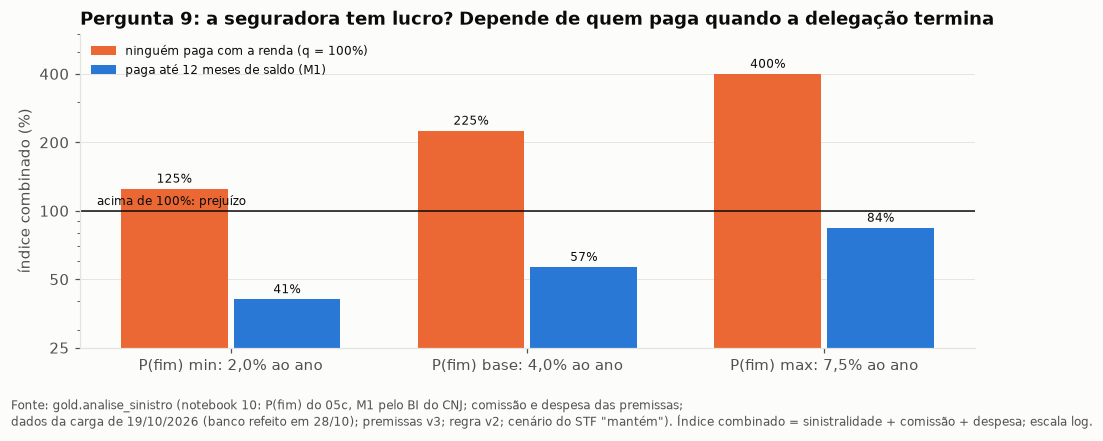

In [6]:
sin = tabs["analise_sinistro"]
cal = tabs["analise_capacidade_calibracao"]
c12 = cal[cal.horizonte_meses == 12].set_index("faixa_deficit")
display(g.tabela(c12.loc[["classe_2", "classe_3"]].reset_index()[["faixa_deficit", "prob_deficit_modelo", "prob_deficit_m1",
                                                                   "pct_descoberto_modelo", "pct_descoberto_m1"]],
                 {c: "pct" for c in ["prob_deficit_modelo", "prob_deficit_m1", "pct_descoberto_modelo", "pct_descoberto_m1"]})
        .rename(columns={"faixa_deficit": "faixa de déficit", "prob_deficit_modelo": "chance de déficit: modelo",
                         "prob_deficit_m1": "chance: M1", "pct_descoberto_modelo": "parte descoberta: modelo",
                         "pct_descoberto_m1": "parte descoberta: M1"}))
print(f"Déficit total: modelo {g.reais(c12.loc['total', 'deficit_modelo'])}; M1 {g.reais(c12.loc['total', 'deficit_m1'])}.")
display(g.tabela(sin[["leitura", "nivel_p_fim", "p_fim", "severidade_q", "sinistralidade", "indice_combinado", "resultado_tecnico"]],
                 {"p_fim": "pct", "severidade_q": "pct", "sinistralidade": "pct", "indice_combinado": "pct", "resultado_tecnico": "reais"})
        .rename(columns={"nivel_p_fim": "P(fim)", "p_fim": "P(fim da delegação no ano)", "severidade_q": "parte da IS que vira sinistro",
                         "indice_combinado": "índice combinado", "resultado_tecnico": "resultado técnico/ano"}))

fig, ax = plt.subplots(figsize=(9, 3.6))
niveis = ["min", "base", "max"]
xs = np.arange(len(niveis))
for j, (leitura, cor, nome) in enumerate([("sem a M1", g.CORES[1], "ninguém paga com a renda (q = 100%)"),
                                         ("com a M1", g.AZUL["medio"], "paga até 12 meses de saldo (M1)")]):
    r = sin[sin.leitura.str.startswith(leitura)].set_index("nivel_p_fim").loc[niveis]
    br = ax.bar(xs + (j - 0.5) * 0.38, 100 * r.indice_combinado, width=0.36, color=cor, label=nome)
    ax.bar_label(br, [g.pct(v, 0) for v in r.indice_combinado], padding=2, fontsize=8)
ax.axhline(100, color=g.TEXTO, linewidth=1)
ax.text(-0.45, 106, "acima de 100%: prejuízo", fontsize=8, ha="left", color=g.TEXTO)
pf = sin.drop_duplicates("nivel_p_fim").set_index("nivel_p_fim").p_fim
ax.set_xticks(xs, [f"P(fim) {nv}: {g.pct(pf[nv])} ao ano" for nv in niveis])
ax.set_ylabel("índice combinado (%)")
ax.set_yscale("log")
ax.set_yticks([25, 50, 100, 200, 400], ["25", "50", "100", "200", "400"])
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set_ylim(25, 600)
ax.grid(axis="x", visible=False)
ax.legend(fontsize=8, loc="upper left")
ax.set_title("Pergunta 9: a seguradora tem lucro? Depende de quem paga quando a delegação termina")
fig.tight_layout()
g.nota(fig, f"Fonte: gold.analise_sinistro (notebook 10: P(fim) do 05c, M1 pelo BI do CNJ; comissão e despesa das premissas;\n{FONTE}). "
            "Índice combinado = sinistralidade + comissão + despesa; escala log.")
g.salvar(fig, "09_pergunta_9")
plt.show()

**O número.**
- Pela M1, **6,9% das obrigadas da Classe 2 e 9,6% das da Classe 3** não pagam o passivo com 12 meses de saldo (a v2 supunha 50% e 30%), mas quem não paga perde muito: 68% e 91% do passivo. As premissas v3 (D-046) usam essa parte descoberta e a chance **ponderada pelo passivo** (10,8% e 18,6%), para o déficit em reais ser o da M1: **R$ 34,1 mi**.
- Com a M1, só 15,8% da IS vira sinistro: sinistralidade de **16% a 59%** (base 32%) e resultado técnico de **R$ 54 mil a R$ 202 mil por ano**.
- Se nenhum titular pagar com a renda, o índice combinado vai de 125% a 400%: **prejuízo** em qualquer P(fim). Com P(fim) de 4% e taxa de 2%, a seguradora só cobre os custos se no máximo 37,5% da IS virar sinistro.

**A frase para a apresentação.** *"Se os titulares conseguirem pagar a dívida com a renda do cartório, o seguro dá lucro. Se não, a taxa de 2% não paga os sinistros: o preço certo depende de quem assume a dívida quando o titular sai."*

**Limitação.** Saldo é renda, não patrimônio, e quando a delegação termina por morte a renda acaba. Isso pode deixar a severidade da M1 baixa no caso mais comum. A P(fim) tem viés de sobrevivência (notebook 05c). 64% do déficit da M1 vem de 50 obrigadas com saldo ≤ 0; conferidas para a D-046, elas têm repasse e custeio altos (dado declarado plausível, não erro de leitura). Sem impostos, resseguro nem capital.

### Achado 6 — Quem é obrigado: Registro de Imóveis e cartórios com 3 ou mais empregados

**A pergunta.** Dá para reconhecer um cartório obrigado pelas atribuições e pelo número de empregados?

**O cálculo.** A referência do notebook 03: entre as serventias com classe conhecida, que parte das que têm cada atribuição ou cada faixa de porte é obrigada (provida e Classe 2 ou 3). Ao lado, as três primeiras regras de associação de `gold.analise_regras` (Apriori, ordem do lift; o lift é quantas vezes a regra acerta mais que a média).

,tipo,item,serventias,obrigadas,% obrigadas
0,atribuição,Notas,1.614,613,"38,0%"
1,atribuição,RCPN,1.386,350,"25,3%"
2,atribuição,RI,314,264,"84,1%"
3,atribuição,RTD,275,165,"60,0%"
4,atribuição,RCPJ,277,166,"59,9%"
5,atribuição,Protesto,297,189,"63,6%"
6,porte (empregados CLT),porte 0 CLT,285,7,"2,5%"
7,porte (empregados CLT),porte 1 a 2 CLT,981,205,"20,9%"
8,porte (empregados CLT),porte 3 a 9 CLT,909,670,"73,7%"
9,porte (empregados CLT),porte 10+ CLT,269,221,"82,2%"


,posicao,se,entao,serventias_com_se,confianca,lift
0,1,RI + porte 3 a 9 CLT,obrigada,161,"87,6%","1,94"
1,2,porte 3 a 9 CLT + região Pouso Alegre,obrigada,98,"83,7%","1,86"
2,3,porte 10+ CLT,obrigada,269,"82,2%","1,82"


Média de MG (classe conhecida): 45,1% obrigadas; 2.447 serventias.


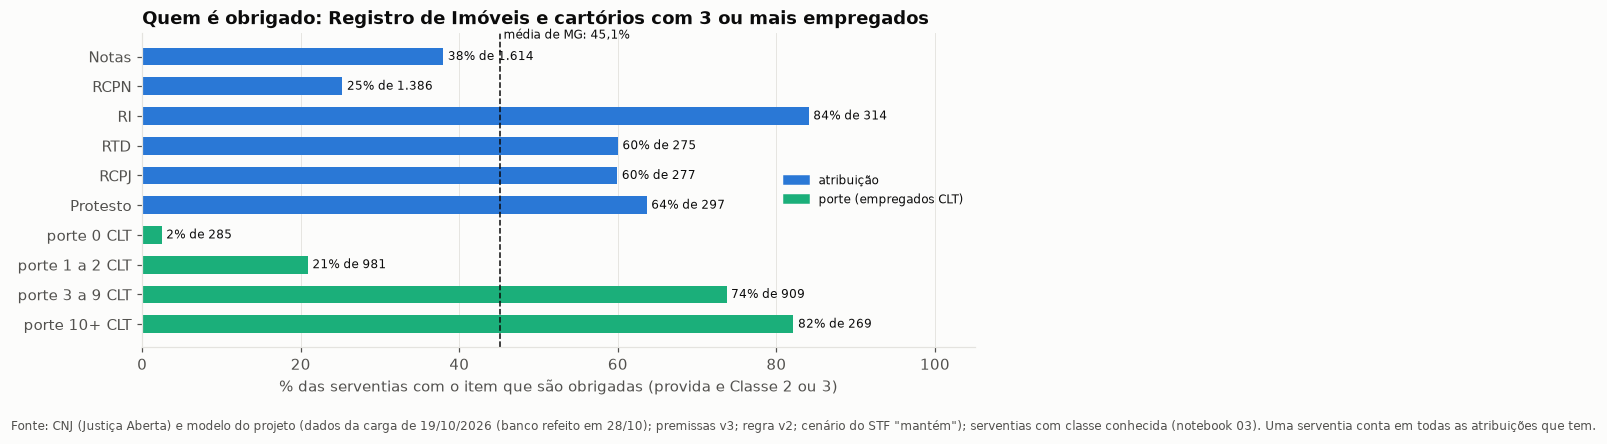

In [7]:
trans = padroes.transacoes(sv)
media_mg = trans[padroes.ALVO].mean()
atrib = padroes.frequencia_por_item(trans, list(padroes.ROTULOS_ATRIBUICOES.values()))
porte = padroes.frequencia_por_item(trans, padroes.faixas_porte())
freq = pd.concat([atrib.assign(tipo="atribuição"), porte.assign(tipo="porte (empregados CLT)")], ignore_index=True)
display(g.tabela(freq[["tipo", "item", "serventias", "com_alvo", "frequencia"]], {"serventias": "int", "com_alvo": "int", "frequencia": "pct"})
        .rename(columns={"com_alvo": "obrigadas", "frequencia": "% obrigadas"}))
rg_ = tabs["analise_regras"].sort_values("posicao")
display(g.tabela(rg_[["posicao", "se", "entao", "serventias_com_se", "confianca", "lift"]].head(3),
                 {"serventias_com_se": "int", "confianca": "pct", "lift": "num2"}))
print(f"Média de MG (classe conhecida): {g.pct(media_mg)} obrigadas; {g.num(len(trans))} serventias.")

fig, ax = plt.subplots(figsize=(9, 3.8))
f = freq.iloc[::-1]
cores = [g.AZUL["medio"] if t == "atribuição" else g.CORES[2] for t in f.tipo]
br = ax.barh(f.item, 100 * f.frequencia, color=cores, height=0.6)
ax.bar_label(br, [f"{g.pct(v, 0)} de {g.num(n)}" for v, n in zip(f.frequencia, f.serventias)], padding=3, fontsize=8)
ax.axvline(100 * media_mg, color=g.TEXTO, linestyle="--", linewidth=1)
ax.text(100 * media_mg, len(f) - 0.4, f" média de MG: {g.pct(media_mg)}", fontsize=8)
ax.set_xlim(0, 105)
ax.set_xlabel("% das serventias com o item que são obrigadas (provida e Classe 2 ou 3)")
ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=g.AZUL["medio"], label="atribuição"), Patch(color=g.CORES[2], label="porte (empregados CLT)")],
          loc="center right", fontsize=8)
ax.set_title("Quem é obrigado: Registro de Imóveis e cartórios com 3 ou mais empregados")
fig.tight_layout()
g.nota(fig, f"Fonte: CNJ (Justiça Aberta) e modelo do projeto ({FONTE}); serventias com classe conhecida (notebook 03). "
            "Uma serventia conta em todas as atribuições que tem.")
g.salvar(fig, "09_quem_e_obrigado")
plt.show()

**O número.** Na média de MG, **45,1%** das serventias com classe conhecida são obrigadas. Com Registro de Imóveis, **84,1%**; com Registro Civil (RCPN), 25,3%. Pelo porte: 2,5% sem empregado, 20,9% com 1 a 2, **73,7% com 3 a 9** e 82,2% com 10 ou mais. A regra mais forte, "RI + 3 a 9 empregados", acerta em 87,6% das 161 serventias com essa combinação (lift 1,94).

**A frase para a apresentação.** *"Cartório de imóveis ou com três ou mais empregados: quase sempre obrigado. Registro civil do interior: quase sempre dispensado."*

**Limitação.** É descrição de 2025, não previsão. As 78 serventias de classe indeterminada ficam fora.

### Achado 7 — Se a norma for lida ao pé da letra, o universo cai 20%

**A pergunta.** O Prov. 213 define a receita da classe como a **receita líquida do repasse** (art. 2º, XXIV). O painel usa a arrecadação bruta. Quanto muda?

**O cálculo.** O mesmo do notebook 08 (seção 5), refeito por `conclusoes.efeito_receita_liquida`: a receita de cada serventia é descontada da fração de repasse que ela declara no BI do CNJ em 2025, o modelo é refeito e a faixa de déficit fica a da base (D-019). É **sensibilidade**: a base do painel não muda.

leitura,medida,base: arrecadação,sensibilidade: arrecadação − repasse,diferença
0,n_universo,"1.121,3","893,6","-20,3%"
1,passivo_universo,"238.104.260,6","225.568.994,8","-5,3%"
2,valor_descoberto,"34.106.243,7","33.181.592,3","-2,7%"
3,mercado_premio_emitido,"341.062,4","331.815,9","-2,7%"


Rótulo: SENSIBILIDADE (D-042, proposta); a base do painel usa a arrecadação.


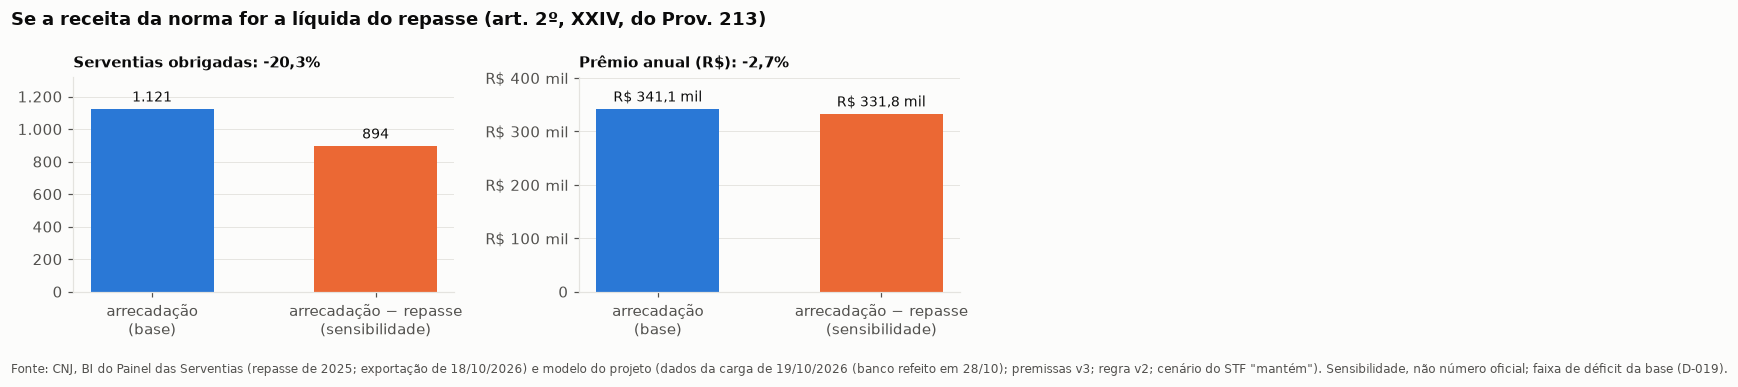

In [8]:
ef = cc.efeito_receita_liquida(con, limites, cenarios)
cols = ["n_universo", "passivo_universo", "valor_descoberto", "mercado_premio_emitido"]
ef_t = ef[cols].T
ef_t["diferença"] = ef_t.iloc[:, 1] / ef_t.iloc[:, 0] - 1
display(g.tabela(ef_t.reset_index(names="medida"), {ef_t.columns[0]: "num1", ef_t.columns[1]: "num1", "diferença": "pct"}))
print("Rótulo: SENSIBILIDADE (D-042, proposta); a base do painel usa a arrecadação.")

fig, axs = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, m, rot, fmt in [(axs[0], "n_universo", "Serventias obrigadas", lambda v: g.num(v)),
                        (axs[1], "mercado_premio_emitido", "Prêmio anual (R$)", g.reais)]:
    br = ax.bar(["arrecadação\n(base)", "arrecadação − repasse\n(sensibilidade)"], ef[m], color=[g.AZUL["medio"], g.CORES[1]], width=0.55)
    ax.bar_label(br, [fmt(v) for v in ef[m]], padding=3, fontsize=9)
    ax.set_title(f"{rot}: {g.pct(ef[m].iloc[1] / ef[m].iloc[0] - 1)}", fontsize=10)
    ax.set_ylim(0, ef[m].max() * 1.18)
    ax.grid(axis="x", visible=False)
    (g.eixo_reais if m.startswith("mercado") else g.eixo_num)(ax)
fig.suptitle("Se a receita da norma for a líquida do repasse (art. 2º, XXIV, do Prov. 213)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
g.nota(fig, "Fonte: CNJ, BI do Painel das Serventias (repasse de 2025; exportação de 18/10/2026) e modelo do projeto "
            f"({FONTE}). Sensibilidade, não número oficial; faixa de déficit da base (D-019).")
g.salvar(fig, "09_receita_liquida")
plt.show()

**O número.** As obrigadas caem de 1.121,3 para **893,6 (−20,3%)**, mas o prêmio cai só **2,7%** (R$ 341,1 mil → R$ 331,8 mil): quem sai é pequeno, perto do limite, e o passivo das obrigadas cai 5,3%. Com as premissas v3, quem sai pesa ainda menos no prêmio (era −8,5% com a v2), porque o déficit ficou concentrado nas grandes.

**A frase para a apresentação.** *"Uma palavra da norma, 'líquida', tira um em cada cinco cartórios do universo, mas menos de 3% do prêmio."*

**Limitação.** A fração de repasse vem de uma exportação manual do BI (data de referência 31/12/2025), e o inciso XXV da mesma norma pode mudar a leitura (notebook 08). Adotar essa leitura na base seria decisão nova do autor (D-043 em diante).

### Achado 8 — Até 2027, o universo cresce de 4% a 11%; o prêmio só cresce se o passivo crescer

**A pergunta.** Quanto o mercado vale em 2026 e 2027?

**O cálculo.** A projeção do notebook 07 (`gold.analise_previsao`): a arrecadação de MG prevista pela tendência log-linear do teste T2, treinada até 2025-2, é distribuída entre as serventias com desvios sorteados do passado (500 sorteios), e o modelo é refeito com a receita de cada ano, com o limite da Classe 1 fixo ou corrigido pelo IPCA (art. 16, § 2º, do Prov. 213), e com o passivo de 2025. Ao lado, o crescimento do passivo de cada ano (M5, notebook 10). **PROJEÇÃO**, nunca número oficial.

Arrecadação de MG (tendência do T2, PROJEÇÃO): 2025 realizado R$ 5,51 bi; 2026: R$ 5,92 bi (soma dos P10 e P90 dos semestres: R$ 5,16 bi a R$ 6,36 bi); 2027: R$ 6,71 bi (soma dos P10 e P90 dos semestres: R$ 5,85 bi a R$ 7,21 bi)


medida                                                                                    mercado_premio_emitido  \
periodo                                                                                                     2026   
variante                                  cenario_limite                                                           
quebra de nível em 2025-2 (sensibilidade) limite corrigido pelo IPCA  R$ 345,0 mil (R$ 328,3 mil a R$ 348,6 mil)   
                                          limite fixo                 R$ 347,6 mil (R$ 331,8 mil a R$ 351,0 mil)   
tendência do T2 (principal)               limite corrigido pelo IPCA  R$ 339,4 mil (R$ 321,6 mil a R$ 343,2 mil)   
                                          limite fixo                 R$ 342,2 mil (R$ 325,2 mil a R$ 346,0 mil)   

medida                                                                                                            \
periodo                                                                                                     2027   
variante                                  cenario_limite                                                           
quebra de nível em 2025-2 (sensibilidade) limite corrigido pelo IPCA  R$ 348,9 mil (R$ 343,5 mil a R$ 353,4 mil)   
                                          limite fixo                 R$ 354,1 mil (R$ 348,8 mil a R$ 358,2 mil)   
tendência do T2 (principal)               limite corrigido pelo IPCA  R$ 343,6 mil (R$ 338,3 mil a R$ 348,3 mil)   
                                          limite fixo                 R$ 349,0 mil (R$ 343,7 mil a R$ 353,5 mil)   

medida                                                                           n_universo  \
periodo                                                                                2026   
variante                                  cenario_limite                                      
quebra de nível em 2025-2 (sensibilidade) limite corrigido pelo IPCA  1.168 (1.042 a 1.197)   
                                          limite fixo                 1.190 (1.066 a 1.220)   
tendência do T2 (principal)               limite corrigido pelo IPCA    1.124 (994 a 1.153)   
                                          limite fixo                 1.147 (1.020 a 1.175)   

medida                                                                                       \
periodo                                                                                2027   
variante                                  cenario_limite                                      
quebra de nível em 2025-2 (sensibilidade) limite corrigido pelo IPCA  1.204 (1.162 a 1.238)   
                                          limite fixo                 1.244 (1.206 a 1.277)   
tendência do T2 (principal)               limite corrigido pelo IPCA  1.161 (1.119 a 1.197)   
                                          limite fixo                 1.204 (1.164 a 1.238)   

medida                                                                       subidas  \
periodo                                                                         2026   
variante                                  cenario_limite                               
quebra de nível em 2025-2 (sensibilidade) limite corrigido pelo IPCA   97 (25 a 126)   
                                          limite fixo                 117 (32 a 147)   
tendência do T2 (principal)               limite corrigido pelo IPCA    62 (14 a 85)   
                                          limite fixo                  78 (19 a 104)   

medida                                                                                 
periodo                                                                          2027  
variante                                  cenario_limite                               
quebra de nível em 2025-2 (sensibilidade) limite corrigido pelo IPCA  146 (108 a 181)  
                                          limite fixo                 190

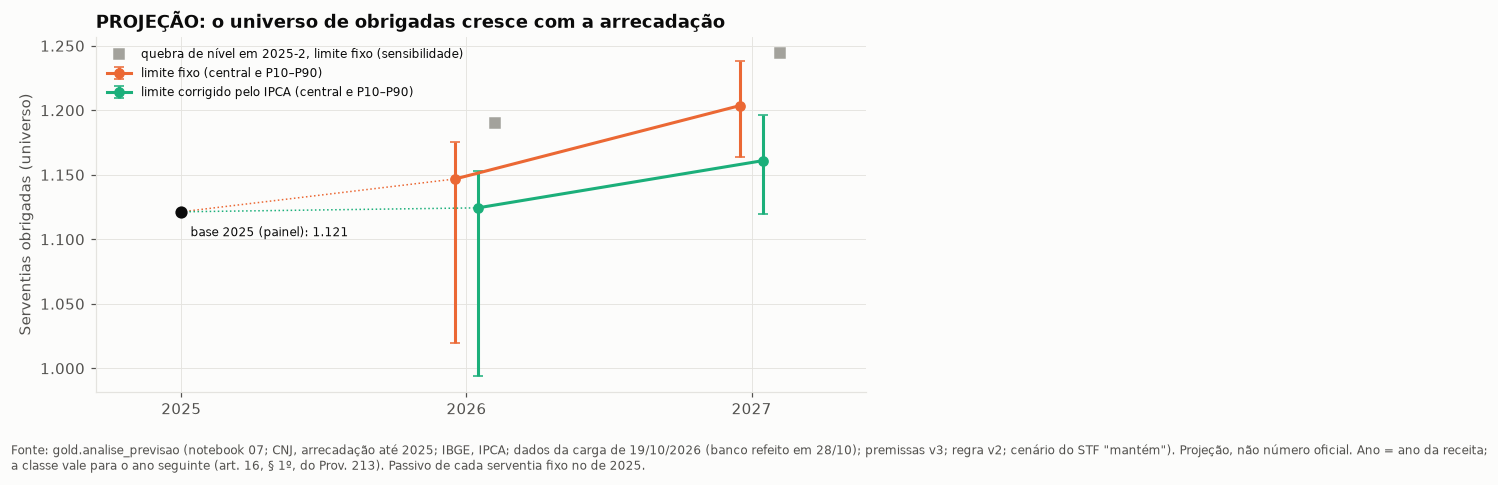

In [9]:
pr = tabs["analise_previsao"]
arr = pr[(pr.bloco == "arrecadacao_mg") & pr.variante.str.contains("principal")].copy()
arr["ano"] = arr.periodo.str[:4].astype(int)
arr_ano = arr.groupby("ano")[["p10", "central", "p90"]].sum()
real_2025 = ler("SELECT sum(arrecadacao) FROM silver.serventia_arrecadacao WHERE versao = 1 AND ano = 2025 AND cns IN "
                "(SELECT cns FROM silver.serventia WHERE status = 'Ativo')", con=con).iloc[0, 0]
print(f"Arrecadação de MG (tendência do T2, PROJEÇÃO): 2025 realizado {g.reais(real_2025, 2)}; " +
      "; ".join(f"{a}: {g.reais(r.central, 2)} (soma dos P10 e P90 dos semestres: {g.reais(r.p10, 2)} a {g.reais(r.p90, 2)})" for a, r in arr_ano.iterrows()))
mer = pr[(pr.bloco == "mercado") & pr.medida.isin(["n_universo", "subidas", "mercado_premio_emitido"])].copy()
mer["valor"] = [f"{g.reais(c) if m.startswith('mercado') else g.num(c)} ({g.reais(a) if m.startswith('mercado') else g.num(a)} a "
                f"{g.reais(z) if m.startswith('mercado') else g.num(z)})" for m, c, a, z in zip(mer.medida, mer.central, mer.p10, mer.p90)]
display(mer.pivot_table(index=["variante", "cenario_limite"], columns=["medida", "periodo"], values="valor", aggfunc="first"))

fig, ax = plt.subplots(figsize=(8, 4))
uni = pr[(pr.bloco == "mercado") & (pr.medida == "n_universo")]
cores = {("tendência do T2 (principal)", "limite fixo"): g.CORES[1], ("tendência do T2 (principal)", "limite corrigido pelo IPCA"): g.CORES[2]}
for k, ((v, c), cor) in enumerate(cores.items()):
    r = uni[(uni.variante == v) & (uni.cenario_limite == c)]
    xs = r.periodo.astype(int).to_numpy() + (k - 0.5) * 0.08
    ax.errorbar(xs, r.central, yerr=[r.central - r.p10, r.p90 - r.central], fmt="o-", color=cor, capsize=3, label=f"{c} (central e P10–P90)")
    ax.plot([2025, xs[0]], [b["obrigadas"], r.central.iloc[0]], color=cor, linestyle=":", linewidth=1)
q_ = uni[uni.variante.str.startswith("quebra") & (uni.cenario_limite == "limite fixo")]
ax.plot(q_.periodo.astype(int) + 0.1, q_.central, "s", color=g.CINZA, label="quebra de nível em 2025-2, limite fixo (sensibilidade)")
ax.plot(2025, b["obrigadas"], "o", color=g.TEXTO, markersize=7)
ax.annotate(f"base 2025 (painel): {g.num(b['obrigadas'])}", (2025, b["obrigadas"]), xytext=(6, -16), textcoords="offset points", fontsize=8)
ax.set_xticks([2025, 2026, 2027], ["2025", "2026", "2027"])
ax.set_xlim(2024.7, 2027.4)
g.eixo_num(ax)
ax.set_ylabel("Serventias obrigadas (universo)")
ax.legend(loc="upper left", fontsize=8)
ax.set_title("PROJEÇÃO: o universo de obrigadas cresce com a arrecadação")
fig.tight_layout()
g.nota(fig, f"Fonte: gold.analise_previsao (notebook 07; CNJ, arrecadação até 2025; IBGE, IPCA; {FONTE}). Projeção, não número oficial. "
            "Ano = ano da receita;\na classe vale para o ano seguinte (art. 16, § 1º, do Prov. 213). Passivo de cada serventia fixo no de 2025.")
g.salvar(fig, "09_projecao_universo")
plt.show()

**O número.**
- MG arrecadou R$ 5,51 bi em 2025; a projeção é de **R$ 5,92 bi em 2026** e **R$ 6,71 bi em 2027**.
- **Obrigadas:** de 1.121 para **1.147 em 2026 e 1.204 em 2027** com o limite fixo (P10–P90 em 2027: 1.164 a 1.238), 1.124 e 1.161 com o limite corrigido e 1.190 e 1.244 com a quebra de nível (sensibilidade). Subidas da Classe 1 para a 2: 78 em 2026 e 147 em 2027 (limite fixo).
- **Prêmio, com o passivo de 2025:** de R$ 341 mil para **R$ 342 mil em 2026 e R$ 349 mil em 2027** (limite fixo); de R$ 339 a 354 mil em todas as variantes. Quem entra é pequeno.
- **Com o passivo de cada ano (M5):** o passivo das obrigadas sobe 14,6% em 2026 e 28,5% em 2027 (tempo de casa e salário corrigido pelo INPC). Como o déficit é proporcional ao passivo, o prêmio subiria na mesma proporção: **≈ R$ 392 mil em 2026 e ≈ R$ 448 mil em 2027** (conta aproximada, com o universo da projeção).

**A frase para a apresentação.** *"Mais cartórios vão passar a ser obrigados, mas os que entram são pequenos. O que faz o mercado crescer até 2027 é a mesma dívida trabalhista ficar maior: os empregados ficam mais tempo e os salários sobem."*

**Limitação.** A previsão principal tende a ser conservadora: o 2026-1 limpo e completado já está 22% acima do 2025-1 (notebook 07), e o autor decidiu não usar uma coleta nova (D-046). A faixa da projeção cobriu o real em só 17% a 40% dos casos no teste no passado (a calibrada pela M3 c cobre 60%). O passivo projetado supõe os mesmos vínculos (sem contratação nem saída).

### Achado 9 — Erros de declaração passaram a pesar no total de MG

**A pergunta.** Os dados de arrecadação são confiáveis para definir a classe?

**O cálculo.** Os saltos grosseiros do notebook 01: o semestre de uma serventia 10 vezes acima ou abaixo da mediana dos seus 4 semestres anteriores. O excesso é o declarado menos essa mediana.

,semestre,arrecadação de MG,saltos,excesso dos saltos,% do total
0,2024-1,"R$ 2,0 bi",12,"R$ 2,3 mi","0,1%"
1,2024-2,"R$ 2,5 bi",26,"R$ 16,3 mi","0,7%"
2,2025-1,"R$ 2,4 bi",13,"R$ 4,3 mi","0,2%"
3,2025-2,"R$ 3,1 bi",32,"R$ 161,3 mi","5,1%"
4,2026-1,"R$ 3,2 bi",44,"R$ 330,3 mi","10,3%"


2026-1: 57 serventias ativas ainda não tinham informado na coleta.


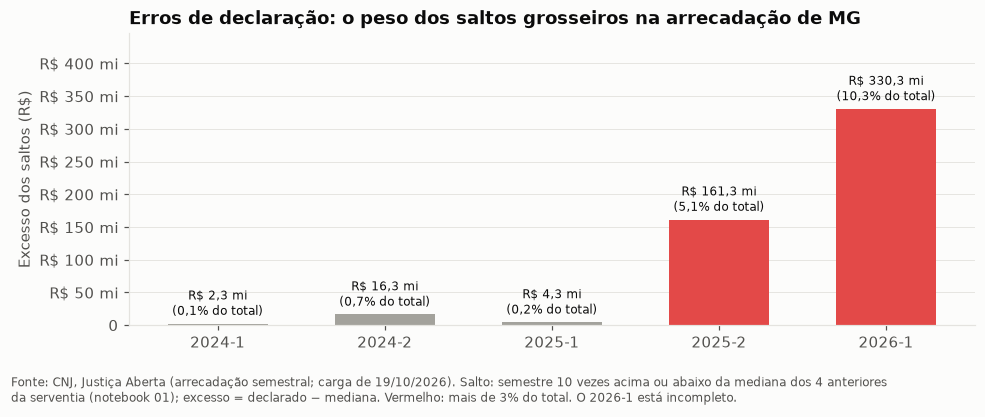

In [10]:
serie = dados.serie_arrecadacao(con)
sal = cc.saltos_por_semestre(serie, 2024)
display(g.tabela(sal.reset_index(names="semestre"), {"arrecadacao_mg": "reais", "saltos": "int", "excesso": "reais", "pct_do_total": "pct"})
        .rename(columns={"arrecadacao_mg": "arrecadação de MG", "excesso": "excesso dos saltos", "pct_do_total": "% do total"}))
nao_inf = int((~serie.loc[serie.periodo == serie.periodo.max(), "informado"]).sum())
print(f"{serie.periodo.max()}: {g.num(nao_inf)} serventias ativas ainda não tinham informado na coleta.")

fig, ax = plt.subplots(figsize=(9, 3.4))
br = ax.bar(sal.index, sal.excesso, color=[g.CORES[7] if v > 0.03 else g.CINZA for v in sal.pct_do_total], width=0.6)
ax.bar_label(br, [f"{g.reais(e)}\n({g.pct(p)} do total)".replace("$", r"\$") for e, p in zip(sal.excesso, sal.pct_do_total)],
             padding=3, fontsize=8)
ax.set_ylim(min(0, sal.excesso.min() * 1.3), sal.excesso.max() * 1.35)
g.eixo_reais(ax)
ax.set_ylabel("Excesso dos saltos (R$)")
ax.grid(axis="x", visible=False)
ax.set_title("Erros de declaração: o peso dos saltos grosseiros na arrecadação de MG")
fig.tight_layout()
g.nota(fig, f"Fonte: CNJ, Justiça Aberta (arrecadação semestral; carga de 19/10/2026). Salto: semestre {cfg['saltos']['fator']} vezes "
            f"acima ou abaixo da mediana dos {cfg['saltos']['janela']} anteriores\nda serventia (notebook 01); excesso = declarado − mediana. "
            f"Vermelho: mais de 3% do total. O {serie.periodo.max()} está incompleto.")
g.salvar(fig, "09_saltos_grosseiros")
plt.show()

**O número.** Até 2025-1, os saltos somavam menos de 1% da arrecadação de MG. Em **2025-2, R$ 161,3 mi (5,1%)**, e no **2026-1, R$ 330,3 mi (10,3%)**, quase todos de três serventias (059816, 042986 e 046219; notebook 07). No universo de 2025, o efeito máximo é de −11 obrigadas, ≈ −1% (notebook 01). O 2026-1 ainda está incompleto (57 serventias sem informar).

**A frase para a apresentação.** *"Um erro de digitação de R$ 100 milhões muda a classe de um cartório e o total do estado. Por isso o sistema agora avisa os saltos."*

**Decidido (D-046):** a classe continua com o valor declarado; o pipeline passou a avisar esses semestres (`qualidade.checagens`: 45 semestres de 2025 em 43 serventias) e a sensibilidade "sem os saltos" mostra o efeito (−11,3 obrigadas, −1,0%; prêmio −0,8%; tabela de lacunas).

**Limitação.** A regra (10 vezes a mediana) é uma suposição (`config/analise.yaml`) e não pega erros menores.

### Achado 10 — Para outros estados, dá para estimar os empregados, mas só o total estadual

**A pergunta.** O CNJ só traz o número de empregados para MG. A receita basta para estimá-los em outros estados?

**O cálculo.** O modelo do notebook 06a (`gold.analise_clt_modelo`): floresta aleatória com a receita e as atribuições, validada deixando cada uma das 13 regiões intermediárias de fora (como se fosse um lugar novo). MAE = erro médio, em empregados por serventia; R² = parte da diferença entre cartórios que o modelo explica.

,método,MAE,RMSE,R2
0,floresta aleatória,"1,86","4,35","0,75"
1,Poisson,"1,93","5,39","0,61"
2,referência: mediana por faixa de receita,"2,34","6,63","0,41"


Floresta: MAE 1,86 × referência 2,34 (20,2% menor). Regiões fora de ±10%: 7 de 13 (maior erro: 25,8%). MG inteiro: previsto 11.562 × declarado 11.864 (-2,5%).


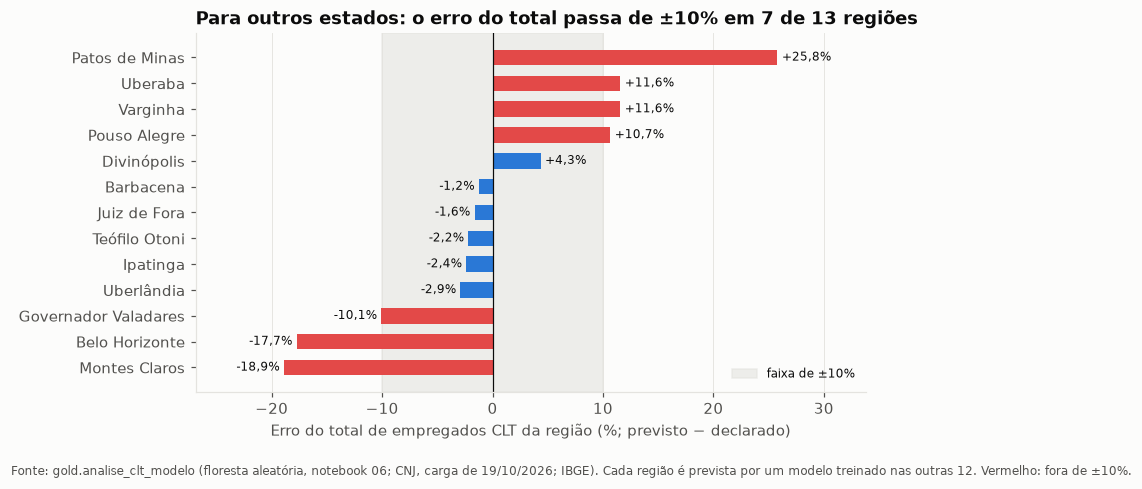

In [11]:
mt, reg = cc.erro_clt(tabs["analise_clt_modelo"])
margem = cfg["regressao"]["margem_total"]
display(g.tabela(mt.reset_index(names="método"), {"MAE": "num2", "RMSE": "num2", "R2": "num2"}))
tot_p, tot_d = reg.clt_previsto_floresta.sum(), reg.clt_declarado.sum()
print(f"Floresta: MAE {g.num(mt.loc['floresta aleatória', 'MAE'], 2)} × referência {g.num(mt.loc['referência: mediana por faixa de receita', 'MAE'], 2)} "
      f"({g.pct(1 - mt.loc['floresta aleatória', 'MAE'] / mt.loc['referência: mediana por faixa de receita', 'MAE'])} menor). "
      f"Regiões fora de ±{g.num(100 * margem)}%: {int((reg.erro_total_pct.abs() > 100 * margem).sum())} de {len(reg)} "
      f"(maior erro: {g.num(reg.erro_total_pct.abs().max(), 1)}%). MG inteiro: previsto {g.num(tot_p)} × declarado {g.num(tot_d)} "
      f"({g.pct(tot_p / tot_d - 1)}).")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.axvspan(-100 * margem, 100 * margem, color=g.GRADE, alpha=0.6, label=f"faixa de ±{g.num(100 * margem)}%")
cores = [g.CORES[7] if abs(e) > 100 * margem else g.AZUL["medio"] for e in reg.erro_total_pct]
br = ax.barh(reg.index, reg.erro_total_pct, color=cores, height=0.6)
ax.bar_label(br, [f"{v:+.1f}%".replace(".", ",") for v in reg.erro_total_pct], padding=3, fontsize=8)
ax.axvline(0, color=g.TEXTO, linewidth=0.8)
ax.set_xlim(reg.erro_total_pct.min() - 8, reg.erro_total_pct.max() + 8)
ax.set_xlabel("Erro do total de empregados CLT da região (%; previsto − declarado)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", fontsize=8)
ax.set_title(f"Para outros estados: o erro do total passa de ±{g.num(100 * margem)}% em {int((reg.erro_total_pct.abs() > 100 * margem).sum())} de {len(reg)} regiões")
fig.tight_layout()
g.nota(fig, "Fonte: gold.analise_clt_modelo (floresta aleatória, notebook 06; CNJ, carga de 19/10/2026; IBGE). Cada região é prevista "
            "por um modelo treinado nas outras 12. Vermelho: fora de ±10%.")
g.salvar(fig, "09_clt_outros_estados")
plt.show()

**O número.** A floresta erra **1,86 empregado por serventia** (R² 0,75), 20,2% menos que a referência (2,34). No total de cada região, o erro passa de ±10% em **7 das 13** (o maior, 25,8%), mas, somando as 13, o total de MG fica só **2,5% abaixo** do declarado (11.562 × 11.864).

**A frase para a apresentação.** *"Fora de MG, o projeto pode estimar os empregados pela receita, com margem de ±10% no total do estado, mas não cartório a cartório nem região a região."*

**Limitação.** Validado só dentro de MG. Antes de publicar outro estado, validar num estado que tenha a contagem do CNJ (D-042).

## 3. Lacunas: o que os dados não responderam

**A pergunta.** O que ficou sem resposta, por quê, e qual fonte nova resolveria?

**Como ler a tabela.** Cada linha é uma lacuna, com o degrau da escada que ela afeta, o motivo, a fonte que resolveria (com o código da melhoria proposta no `plano_mineracao.md`, M1 a M10), se a fonte é pública e gratuita, se existe para todos os estados e quanto a lacuna mexe no resultado. As faixas do prêmio vêm do tornado e do Monte Carlo (achados 2 e 3); a taxa de vacância é recalculada do cadastro do CNJ como no notebook 05c; a sinistralidade é a das premissas (SES da SUSEP, igual na v2 e na v3); o resultado técnico, de `gold.fato_mercado_uf`. O "−11 obrigadas" é citado do notebook 01.

In [12]:
tor_i = tor.set_index("suposicao")
def faixa_tor(nomes):
    t = tor_i.loc[nomes]
    return f"{g.reais(t[['premio_no_min', 'premio_no_max']].min().min())} a {g.reais(t[['premio_no_min', 'premio_no_max']].max().max())}"
cad = dados.cadastro_cnj(["MG"])
coleta = pd.Timestamp(ler("SELECT data_referencia FROM silver.fonte_metadados WHERE fonte = 'cnj_serventias'", con=con).iloc[0, 0])
tx = va.taxas_por_ano(cad, range(cfg["vacancia"]["inicio_confiavel"], coleta.year + 1), sem_lote=False).set_index("ano")
fracao_ano = coleta.dayofyear / pd.Timestamp(coleta.year, 12, 31).dayofyear
tx_21_23, tx_25, tx_26 = tx.loc[2021:2023, "taxa"].mean(), tx.loc[2025, "taxa"], tx.loc[coleta.year, "taxa"] / fracao_ano
sin_p = semente_premissas["premissas"]["sinistralidade"]["valores"]
res = ler("""SELECT nivel, mercado_resultado_tecnico FROM gold.fato_mercado_uf WHERE regra_classe = 'v2' AND cenario_stf = 'mantem'""",
          con=con).set_index("nivel").mercado_resultado_tecnico
pq = tabs["analise_previsao"]
u27 = pq[(pq.bloco == "mercado") & (pq.medida == "n_universo") & (pq.periodo == "2027")].central
sm = tabs["analise_sensibilidade_metodo"].set_index("chave")
s_m1 = sin[sin.leitura.str.startswith("com")].set_index("nivel_p_fim")

lacunas = pd.DataFrame([
    ("Patrimônio livre do titular", "5 e 6 (quem tem déficit e quanto)",
     "Patrimônio de pessoa física não é publicado (sigilo fiscal).",
     "Saldo anual do titular (arrecadação − repasse − custeio) no BI do CNJ, como aproximação (M1, notebook 10): é "
     "renda, não patrimônio. Usado desde a D-046 (premissas v3)",
     "sim (BI do CNJ, já no bronze)", "sim (arquivo nacional)",
     f"as 4 suposições de patrimônio juntas levam o P5–P95 do prêmio a {g.reais(pm.loc['patrimônio junto', 'p05'])} a "
     f"{g.reais(pm.loc['patrimônio junto', 'p95'])}; o horizonte de saldo (6 a 24 meses, suposição) é o que sobra de incerteza"),
    ("Taxa cobrada pelas seguradoras", "8 (prêmio)",
     "O produto é novo: nenhuma apólice do Prov. 227 foi emitida ainda.",
     "Cotação com seguradoras (não é dado público). A SES da SUSEP não publica a importância segurada (conferido em 28/10, M8): "
     "a taxa média não sai dela",
     "prêmio: sim; IS: não", "sim", f"sozinha, o prêmio vai de {faixa_tor(['taxa'])}; com a adesão, de "
     f"{g.reais(grade.min().min())} a {g.reais(grade.max().max())} (grade da M8)"),
    ("Escolha pelo seguro (adesão)", "7 (IS)",
     "A norma permite bens, fiança ou seguro, e ninguém escolheu ainda.",
     "Garantias apresentadas às corregedorias depois da vigência (não existe hoje)", "não existe hoje", "—",
     f"sozinha, o prêmio vai de {faixa_tor(['seguro'])}"),
    ("Chance de a delegação terminar no ano (D-025)", "9 (sinistro por frequência)",
     "O cadastro do CNJ só traz a situação atual, e as datas foram sobrescritas no recadastramento de 2024 (notebook 05c).",
     "Coletas do cadastro com meses de distância (M9, não feita: D-046)", "sim", "sim",
     f"taxa de vacância observada em MG: {g.pct(tx_21_23)} ao ano em 2021–23, {g.pct(tx_25)} em 2025 e {g.pct(tx_26)} em "
     f"{coleta.year} (anualizada; com viés de sobrevivência, notebook 05c)"),
    ("Sinistros do seguro dos cartórios (resultado da seguradora)", "9 (lucro da seguradora)",
     "O ramo é novo; a SES só tem a garantia de obrigações públicas e privadas (outro risco).",
     "SES da SUSEP depois de 1 a 2 anos de vigência; até lá, a conta por frequência × severidade (M2, feita no notebook 10)",
     "sim", "sim",
     f"pela M2 com a M1, sinistralidade de {g.pct(s_m1.loc['min', 'sinistralidade'])} a {g.pct(s_m1.loc['max', 'sinistralidade'])} "
     f"e resultado técnico de {g.reais(s_m1.loc['max', 'resultado_tecnico'])} a {g.reais(s_m1.loc['min', 'resultado_tecnico'])} por "
     f"ano; se ninguém pagar com a renda, prejuízo (SES de {g.pct(sin_p['min'])} a {g.pct(sin_p['max'])})"),
    ("Arrecadação de 2026-1 completa", "3 (universo projetado)",
     f"Na carga, {g.num(nao_inf)} serventias ainda não tinham informado o {serie.periodo.max()}.",
     "Uma coleta nova do Justiça Aberta depois do prazo de declaração (o autor decidiu ficar com a de 18/10, D-046)",
     "sim", "sim",
     f"obrigadas em 2027 (central): {g.num(u27.min())} a {g.num(u27.max())} no notebook 07"),
    ("Declarações com salto grosseiro", "3 (universo)",
     "Erro de digitação provável na fonte; a classe usa o valor declarado (D-010, D-046).",
     "Correção pelo próprio cartório no Justiça Aberta; até lá, aviso no pipeline e sensibilidade (D-046)", "sim", "sim",
     f"sem os saltos: {g.num(sm.loc['sem_saltos', 'n_universo'] - sm.loc['base', 'n_universo'], 1)} obrigadas "
     f"({g.pct(sm.loc['sem_saltos', 'var_n_universo'])}) e prêmio {g.pct(sm.loc['sem_saltos', 'var_mercado_premio_emitido'])}"),
    ("Empregados CLT em outros estados", "2 e 4 (expansão)",
     "O CNJ só traz a contagem de empregados para MG (teste T1).",
     "Modelo de CLT pela receita (floresta do T1), com a RAIS como conferência (D-042)", "sim", "sim",
     f"erro do total de uma região não vista de até {g.num(reg.erro_total_pct.abs().max(), 0)}%; publicar o total estadual com "
     f"±{g.num(100 * margem)}%"),
], columns=["lacuna", "degrau da escada", "por que os dados não respondem", "fonte nova que resolveria", "pública e gratuita?",
            "existe para todos os estados?", "quanto muda a análise"])
with pd.option_context("display.max_colwidth", None):
    display(lacunas)

,lacuna,degrau da escada,por que os dados não respondem,fonte nova que resolveria,pública e gratuita?,existe para todos os estados?,quanto muda a análise
0,Patrimônio livre do titular,5 e 6 (quem tem déficit e quanto),Patrimônio de pessoa física não é publicado (sigilo fiscal).,"Saldo anual do titular (arrecadação − repasse − custeio) no BI do CNJ, como aproximação (M1, notebook 10): é renda, não patrimônio. Usado desde a D-046 (premissas v3)","sim (BI do CNJ, já no bronze)",sim (arquivo nacional),"as 4 suposições de patrimônio juntas levam o P5–P95 do prêmio a R$ 197,2 mil a R$ 748,4 mil; o horizonte de saldo (6 a 24 meses, suposição) é o que sobra de incerteza"
1,Taxa cobrada pelas seguradoras,8 (prêmio),O produto é novo: nenhuma apólice do Prov. 227 foi emitida ainda.,"Cotação com seguradoras (não é dado público). A SES da SUSEP não publica a importância segurada (conferido em 28/10, M8): a taxa média não sai dela",prêmio: sim; IS: não,sim,"sozinha, o prêmio vai de R$ 170,5 mil a R$ 596,9 mil; com a adesão, de R$ 85,3 mil a R$ 835,6 mil (grade da M8)"
2,Escolha pelo seguro (adesão),7 (IS),"A norma permite bens, fiança ou seguro, e ninguém escolheu ainda.",Garantias apresentadas às corregedorias depois da vigência (não existe hoje),não existe hoje,—,"sozinha, o prêmio vai de R$ 170,5 mil a R$ 477,5 mil"
3,Chance de a delegação terminar no ano (D-025),9 (sinistro por frequência),"O cadastro do CNJ só traz a situação atual, e as datas foram sobrescritas no recadastramento de 2024 (notebook 05c).","Coletas do cadastro com meses de distância (M9, não feita: D-046)",sim,sim,"taxa de vacância observada em MG: 1,8% ao ano em 2021–23, 7,5% em 2025 e 4,0% em 2026 (anualizada; com viés de sobrevivência, notebook 05c)"
4,Sinistros do seguro dos cartórios (resultado da seguradora),9 (lucro da seguradora),O ramo é novo; a SES só tem a garantia de obrigações públicas e privadas (outro risco).,"SES da SUSEP depois de 1 a 2 anos de vigência; até lá, a conta por frequência × severidade (M2, feita no notebook 10)",sim,sim,"pela M2 com a M1, sinistralidade de 15,8% a 59,1% e resultado técnico de R$ 53,9 mil a R$ 201,7 mil por ano; se ninguém pagar com a renda, prejuízo (SES de 1,7% a 73,9%)"
5,Arrecadação de 2026-1 completa,3 (universo projetado),"Na carga, 57 serventias ainda não tinham informado o 2026-1.","Uma coleta nova do Justiça Aberta depois do prazo de declaração (o autor decidiu ficar com a de 18/10, D-046)",sim,sim,obrigadas em 2027 (central): 1.161 a 1.244 no notebook 07
6,Declarações com salto grosseiro,3 (universo),"Erro de digitação provável na fonte; a classe usa o valor declarado (D-010, D-046).","Correção pelo próprio cartório no Justiça Aberta; até lá, aviso no pipeline e sensibilidade (D-046)",sim,sim,"sem os saltos: -11,3 obrigadas (-1,0%) e prêmio -0,8%"
7,Empregados CLT em outros estados,2 e 4 (expansão),O CNJ só traz a contagem de empregados para MG (teste T1).,"Modelo de CLT pela receita (floresta do T1), com a RAIS como conferência (D-042)",sim,sim,erro do total de uma região não vista de até 26%; publicar o total estadual com ±10%


**O que encontramos.**
- As três maiores lacunas (**patrimônio do titular, taxa e adesão**) são as que mais mexem no prêmio e **nenhuma tem fonte pública**. Para o patrimônio, a aproximação pela renda (M1) já está na base desde a D-046 (premissas v3): o déficit caiu 7,5% e ficou concentrado nas grandes. A taxa **não sai da SES** (a SUSEP não publica a importância segurada; M8). Taxa e adesão só vão existir depois que o mercado começar.
- A **pergunta 9** (a seguradora tem lucro?) ganhou uma resposta própria (achado 5, M2), condicionada a quem paga quando a delegação termina. A SES continua de outro risco.
- O autor decidiu ficar com os dados coletados em 17 e 18/10 (D-046). O 2026-1 completo e uma segunda leitura do cadastro ficam para uma coleta futura.

**Limitações.** As colunas "pública e gratuita" e "todos os estados" refletem o que o projeto já usa ou conferiu.

## 4. Recomendação para o painel (insumo das Etapas 3 e 4)

Onde cada achado entra, seguindo as páginas do `docs/plano_projeto.md` (Etapa 3). Toda projeção vai com o rótulo "projeção" e toda sensibilidade com o rótulo da D-042; todo gráfico, com fonte e data de referência.

In [13]:
recomendacao = pd.DataFrame([
    (1, "A escada do mercado", "09_escada_do_mercado", "Início (abaixo dos 10 números)"),
    (2, "Faixa provável do prêmio e cenário do STF", "09_faixa_do_premio (ou 08_monte_carlo_premio); prêmio condicionado ao cenário (M7)",
     "Início, logo abaixo do déficit, da IS e do prêmio (D-042)"),
    (3, "O que mais mexe no prêmio", "09_tornado_resumo e 10_grade_taxa_adesao (ao vivo no simulador)", "Simulador"),
    (4, "Mercado concentrado e cliente do seguro", "09_concentracao e 09_grupo_alvo (ou 10_capacidade_de_pagar)", "Mercado"),
    (5, "A seguradora tem lucro? (pergunta 9)", "09_pergunta_9 (ou 10_sinistralidade)", "Simulador (resultado da seguradora)"),
    (6, "Quem é obrigado", "09_quem_e_obrigado", "Mercado"),
    (7, "Leitura literal da receita", "09_receita_liquida", "Qualidade dos dados (sensibilidade)"),
    (8, "Projeção 2026–27", "09_projecao_universo (gold.analise_previsao)", "Análises (página nova), rotulada como projeção"),
    (9, "Erros de declaração", "09_saltos_grosseiros", "Qualidade dos dados"),
    (10, "CLT em outros estados", "09_clt_outros_estados", "Análises (só depois da expansão; hoje, nota de método)"),
    ("—", "Lacunas", "tabela da seção 3", "Qualidade dos dados"),
], columns=["achado", "tema", "gráfico (docs/qa/analises/)", "página do painel"])
with pd.option_context("display.max_colwidth", None):
    display(recomendacao)

,achado,tema,gráfico (docs/qa/analises/),página do painel
0,1,A escada do mercado,09_escada_do_mercado,Início (abaixo dos 10 números)
1,2,Faixa provável do prêmio e cenário do STF,09_faixa_do_premio (ou 08_monte_carlo_premio); prêmio condicionado ao cenário (M7),"Início, logo abaixo do déficit, da IS e do prêmio (D-042)"
2,3,O que mais mexe no prêmio,09_tornado_resumo e 10_grade_taxa_adesao (ao vivo no simulador),Simulador
3,4,Mercado concentrado e cliente do seguro,09_concentracao e 09_grupo_alvo (ou 10_capacidade_de_pagar),Mercado
4,5,A seguradora tem lucro? (pergunta 9),09_pergunta_9 (ou 10_sinistralidade),Simulador (resultado da seguradora)
5,6,Quem é obrigado,09_quem_e_obrigado,Mercado
6,7,Leitura literal da receita,09_receita_liquida,Qualidade dos dados (sensibilidade)
7,8,Projeção 2026–27,09_projecao_universo (gold.analise_previsao),"Análises (página nova), rotulada como projeção"
8,9,Erros de declaração,09_saltos_grosseiros,Qualidade dos dados
9,10,CLT em outros estados,09_clt_outros_estados,"Análises (só depois da expansão; hoje, nota de método)"


## 5. Resumo

1. **Quanto dinheiro:** R$ 341,1 mil de prêmio por ano em MG na base (R$ 17,1 mi garantidos sobre R$ 238,1 mi de passivo das obrigadas); teto teórico de R$ 4,76 mi.
2. **Quão certo:** provavelmente entre **R$ 215 mil e R$ 687 mil** (P5–P95), não entre R$ 52 mil e R$ 1,9 mi; a incerteza vem quase toda de **taxa e adesão**, que ninguém conhece antes de o mercado existir.
3. **Quem é o cliente:** as **providas grandes** (11% dos cartórios agrupados, 67% do passivo das obrigadas e 78% do déficit; 85% serventia a serventia pela capacidade de pagar); RI e porte de 3 ou mais empregados definem quem é obrigado.
4. **A seguradora tem lucro?** Se os titulares pagarem com a renda o que conseguem, sim (sinistralidade de 16% a 59%); se ninguém pagar, a taxa de 2% não cobre os sinistros.
5. **O que pode mudar o número:** o STF (suspensão = zero), a leitura literal da receita (−20% no universo, só −2,7% no prêmio), o passivo até 2027 (prêmio de ≈ R$ 392 mil em 2026 e ≈ R$ 448 mil em 2027 com o passivo de cada ano, projeção) e os erros de declaração (até 10% do total de um semestre; na classe, −1%).
6. **O que falta:** patrimônio do titular (hoje aproximado pela renda), taxa e adesão, sem fonte pública; o 2026-1 completo e coletas do cadastro com meses de distância.

**Para o cálculo do painel:** a base mudou uma vez nesta etapa, pela D-046 (premissas v3: déficit pela capacidade de pagar). As outras decisões pendentes do autor estão no `docs/ESTADO_ATUAL.md` (D-042, limite fixo × corrigido).